<a href="https://colab.research.google.com/github/Pascingo/CTA-media-analysis/blob/main/Stage_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# Packages (in Colab every session; locally only the first time)
%pip install -q -r https://raw.githubusercontent.com/Pascingo/CTA-media-analysis/main/requirements.txt
%pip install -q ftfy rapidfuzz ollama pyarrow "anatoolbox[embeddings] @ https://github.com/umagira/anatoolbox/archive/refs/heads/main.zip"
import os
import re
import json
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import gdown
from tqdm.auto import tqdm
import hashlib
from sentence_transformers import SentenceTransformer
import textwrap
import time
from IPython.display import Markdown, display

# Same settings as in Stage 1
TEXT_COLUMN = "content"
START_DATE = "2024-09-01"
END_DATE = "2026-08-31"

GOVERNANCE_KEYWORDS = [
    "security", "accountability", "bias", "fairness",
    "regulatory", "regulation", "governance", "policy",
    "ethics", "compliance", "law"
]
MIN_KEYWORD_HITS = 5
RANDOM_STATE = 42

# Folders and files
DATA_FOLDER = "data"

# Stage 3 results are saved on Google Drive, so that caches survive a runtime reset
import torch

# Computing device: NVIDIA GPU, Apple Silicon GPU or CPU
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")

# Google Drive: mounted in Colab, synchronised by "Google Drive for desktop" on a local computer
LOCAL_DRIVE_ROOT = None   # set manually if not found, e.g. "G:/Meine Ablage" or "/Users/name/Library/CloudStorage/GoogleDrive-.../My Drive"

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_ROOT = Path("/content/drive/MyDrive")
elif LOCAL_DRIVE_ROOT:
    DRIVE_ROOT = Path(LOCAL_DRIVE_ROOT)
else:
    candidates = []
    for base in [Path.home() / "Library" / "CloudStorage", Path.home()]:          # macOS
        for name in ["My Drive", "Meine Ablage"]:
            candidates += list(base.glob(f"GoogleDrive-*/{name}"))
    for letter in "GHIJK":                                                        # Windows
        for name in ["My Drive", "Meine Ablage"]:
            candidates.append(Path(f"{letter}:/{name}"))
    DRIVE_ROOT = next((c for c in candidates if c.exists()), None)
    if DRIVE_ROOT is None:
        raise FileNotFoundError("Google Drive folder not found. Set LOCAL_DRIVE_ROOT above.")

STAGE3_FOLDER = str(DRIVE_ROOT / "NLP_Projekt" / "stage3")
if not os.path.exists(STAGE3_FOLDER):
    raise FileNotFoundError(f"{STAGE3_FOLDER} not found. Check the Drive folder or its shortcut.")

print(f"Running in {'Colab' if IN_COLAB else 'local Jupyter'} | device: {DEVICE} | Stage 3 folder: {STAGE3_FOLDER}")

DRIVE_FOLDER_URL = "https://drive.google.com/drive/folders/14cAxvtxuTfwENtSDCmGcRpl6qhl-z62z"

DATASET_FILE     = os.path.join(DATA_FOLDER, "ai_media_dataset_20260911.csv")
STAGE1_GOV_FILE  = os.path.join(DATA_FOLDER, "ai_governance_cleaned.csv")
ENTITIES_FILE    = os.path.join(DATA_FOLDER, "entities_spacy.csv")
LANGEXTRACT_FILE = os.path.join(DATA_FOLDER, "langextract_ollama_25pm.jsonl")
os.makedirs(DATA_FOLDER, exist_ok=True)


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Running in local Jupyter | device: mps | Stage 3 folder: /Users/pascalingold/Library/CloudStorage/GoogleDrive-pascal.mscids@gmail.com/My Drive/NLP_Projekt/stage3


### Download of the Stage 1 data (Pascal)

We download the files from our public Google Drive folder: the fixed dataset version (2026-09-11), the Stage 1 governance corpus, the spaCy entities and the LangExtract results. The download is skipped if the files are already in the folder `data`.

In [7]:
STAGE1_FILES = [DATASET_FILE, STAGE1_GOV_FILE, ENTITIES_FILE, LANGEXTRACT_FILE]

if not all(os.path.exists(f) for f in STAGE1_FILES):
    gdown.download_folder(DRIVE_FOLDER_URL, output=DATA_FOLDER, quiet=True)

for f in STAGE1_FILES:
    if not os.path.exists(f):
        raise FileNotFoundError(f"{f} not found. Please check the Google Drive folder.")
    print(f"{f:<45} {os.path.getsize(f) / 1e6:>8.1f} MB")

data/ai_media_dataset_20260911.csv               529.7 MB
data/ai_governance_cleaned.csv                   438.6 MB
data/entities_spacy.csv                          220.6 MB
data/langextract_ollama_25pm.jsonl                 2.7 MB


### Reconstructing the Stage 1 corpus with document IDs (Pascal)

In Stage 1 we saved the governance corpus without its index. The spaCy entities and the LangExtract results, however, refer to the articles by this index (`doc_id`). We therefore repeat the cleaning steps of Stage 1 on the original dataset. The steps are deterministic, so we get the same articles with the same `doc_id`.

Two checks make sure this worked:

1. The number of articles and the titles must be identical to `ai_governance_cleaned.csv`.
2. All `doc_id`s in the LangExtract results must exist in the reconstructed corpus.

We keep the **full cleaned corpus** (`df`), and not only the 12,393 Stage 1 articles. The new topic filter in Part 1 has to be evaluated on all articles, so that we also see relevant articles that the Stage 1 filter missed (recall). The column `in_stage1` marks the articles of the Stage 1 corpus.

In [8]:
# 1. Same cleaning as in Stage 1 (sections 2 and 3)
df = pd.read_csv(DATASET_FILE, usecols=["title", "date", "content", "domain", "url", "tags"])
df = df.dropna(subset=[TEXT_COLUMN])
df = df.drop_duplicates(subset=[TEXT_COLUMN])

df["published_at"] = pd.to_datetime(df["date"], errors="coerce")
df = df[(df["published_at"] >= START_DATE) & (df["published_at"] <= END_DATE)].copy()

df["cleaned_text"] = df[TEXT_COLUMN].apply(
    lambda t: unicodedata.normalize("NFKD", t).encode("ascii", "ignore").decode()
)
df["cleaned_text"] = (
    df["cleaned_text"]
    .str.lower()
    .str.replace(r"<[^>]+>", " ", regex=True)
    .str.replace(r"[-/]", " ", regex=True)
    .str.replace(r"[^a-z0-9\s.,!?]", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

pattern = r"\b(?:" + "|".join(GOVERNANCE_KEYWORDS) + r")\b"
df["gov_keyword_hits"] = df["cleaned_text"].str.count(pattern)
df["in_stage1"] = df["gov_keyword_hits"] >= MIN_KEYWORD_HITS
df.index.name = "doc_id"

# 2. Check 1: same articles as the saved Stage 1 corpus
df_gov_s1 = pd.read_csv(STAGE1_GOV_FILE)
stage1_ids = df.index[df["in_stage1"]]

assert len(stage1_ids) == len(df_gov_s1), "Number of articles differs from Stage 1."
assert (
    df.loc[stage1_ids, "title"].fillna("").values == df_gov_s1["title"].fillna("").values
).all(), "Titles differ from Stage 1."

# Take over the columns computed in Stage 1 (spaCy lemmas, sentiment)
for col in ["processed_text", "sentiment_polarity"]:
    df.loc[stage1_ids, col] = df_gov_s1[col].values

# 3. Check 2: the LangExtract results refer to existing articles
lx_doc_ids = pd.read_json(LANGEXTRACT_FILE, lines=True)["doc_id"]
share_found = lx_doc_ids.isin(stage1_ids).mean()
assert share_found == 1.0, f"Only {share_found:.1%} of the LangExtract doc_ids were found."

print(f"Full cleaned corpus:        {len(df):>6,} articles")
print(f"Stage 1 governance corpus:  {df['in_stage1'].sum():>6,} articles")
print(f"LangExtract articles found: {lx_doc_ids.nunique():>6,} (100%)")

Full cleaned corpus:        47,444 articles
Stage 1 governance corpus:  12,393 articles
LangExtract articles found:    599 (100%)


# 1. Addressing the Stage 1 feedback

The feedback on Stage 1 named three problems:

1. Several topics of our corpus are about **broader politics, energy and enterprise technology** rather than AI Governance. Our topic filter was too broad.
2. The relation extraction produced many **inconsistent predicates** and **source-alignment problems**. After schema filtering, very few factual relations remained.
3. The co-occurrence graph is useful for exploration, but it is **not factual evidence**.

These problems directly affect the RAG system: irrelevant articles become irrelevant retrieved passages, and wrong relations become wrong "facts" in the answers. We therefore address them first.

## 1.1 Tightened topic filter (Pascal)

The Stage 1 filter counted eleven general keywords and kept every article with at least 5 hits. It had two weaknesses:

- **Generic words** such as *security*, *policy* and *law* also appear in articles about cybersecurity products, US domestic politics or company policies.
- **Absolute counts** favour long articles: a 4,000-word article about energy markets reaches 5 hits easily, even if governance is only a side remark.

The new filter works in three steps:

1. **Governance score:** We count specific governance terms in two groups. *Strong terms* (e.g. *AI Act*, *code of practice*, *AI safety institute*, *copyright*, *lawsuit*) are clearly about governance on their own and get weight 3. *Medium terms* (e.g. *regulation*, *accountability*, *bias*, *oversight*) get weight 1. The generic words *security*, *policy* and *law* are no longer counted. We divide the weighted hits by the article length (**hits per 1,000 words**), so that long articles are not favoured.
2. **Off-topic score:** For the three confounders named in the feedback (politics, energy, enterprise technology), we count typical terms in the same way. The term lists are based on our Stage 1 topics 2, 3, 4, 5 and 7.
3. **Decision rule:** An article is kept if governance is dense enough, appears in the title or across several distinct terms, and is **at least as dense as the strongest off-topic vocabulary**. In other words, governance has to be the main subject, not a side remark.

The thresholds in this section are **provisional**. In section 1.2 we evaluate the filter on a manually annotated sample and choose the final thresholds there.

In [9]:
import hashlib

# Strong terms: clearly about AI Governance on their own (weight 3)
STRONG_TERMS = [
    r"ai act", r"code of practice", r"ai (?:safety|security) institutes?",
    r"executive orders?", r"gdpr", r"digital services act", r"responsible ai",
    r"ai governance", r"ai regulations?", r"ai safety", r"ai ethics",
    r"algorithmic bias", r"sb 53", r"sb 1047", r"frontier ai", r"deepfakes?",
    r"copyright", r"lawsuits?", r"data protection", r"ai liability",
    # AI security is part of our track
    r"ai security", r"prompt injections?", r"adversarial attacks?", r"(?:data|model) poisoning",
]

# Medium terms: typical governance vocabulary (weight 1)
MEDIUM_TERMS = [
    r"regulations?", r"regulatory", r"regulators?", r"legislation", r"lawmakers?",
    r"governance", r"accountability", r"fairness", r"bias(?:es|ed)?", r"discrimination",
    r"ethic(?:s|al)", r"transparency", r"oversight", r"liability", r"compliance",
    r"privacy", r"audits?", r"watermark(?:s|ing)?", r"red teaming", r"jailbreaks?",
    r"misinformation", r"ai risks?",
]

# Off-topic vocabulary for the three confounders named in the feedback
OFFTOPIC_TERMS = {
    "politics": [
        r"elections?", r"campaigns?", r"voters?", r"democrats?", r"republicans?",
        r"tariffs?", r"trade war", r"immigration", r"ukraine", r"russia",
        r"israel", r"gaza", r"iran", r"nato", r"military",
    ],
    "energy": [
        r"energy", r"electricity", r"power grids?", r"grid", r"nuclear",
        r"gigawatts?", r"megawatts?", r"utilities", r"oil", r"gas", r"solar",
        r"emissions", r"data centers?",
    ],
    "enterprise": [
        r"revenue", r"earnings", r"quarterly", r"shares", r"stock", r"investors?",
        r"valuation", r"funding round", r"ipo", r"customers?", r"enterprises?",
        r"saas", r"hybrid cloud", r"red hat", r"kubernetes", r"apis?",
        r"developers?", r"workflows?", r"productivity", r"mcp",
    ],
}


def count_terms(texts, terms, desc):
    """Count every term in every text in ONE pass per text.
    Each term is its own capture group; match.lastindex tells us which term matched."""
    regex = re.compile("|".join(rf"(\b{t}\b)" for t in terms))
    counts = np.zeros((len(texts), len(terms)), dtype=np.int32)
    for i, text in enumerate(tqdm(texts, desc=desc)):
        for match in regex.finditer(text):
            counts[i, match.lastindex - 1] += 1
    return pd.DataFrame(counts, columns=terms, index=texts.index)


# Cache: the file name contains a hash of the term lists,
# so the features are recomputed automatically when a list changes
term_hash = hashlib.md5(
    json.dumps([STRONG_TERMS, MEDIUM_TERMS, OFFTOPIC_TERMS]).encode()
).hexdigest()[:8]
TOPIC_FEATURES_FILE = os.path.join(STAGE3_FOLDER, f"topic_features_{term_hash}.parquet")

df["cleaned_title"] = (
    df["title"].fillna("").astype(str).str.lower()
    .str.replace(r"[-/]", " ", regex=True)
    .str.replace(r"[^a-z0-9\s.,!?]", "", regex=True)
)
df["n_words"] = df["cleaned_text"].str.count(" ") + 1

if os.path.exists(TOPIC_FEATURES_FILE):
    features = pd.read_parquet(TOPIC_FEATURES_FILE)
    print("Loaded topic features from cache.")
else:
    strong_counts = count_terms(df["cleaned_text"], STRONG_TERMS, "strong terms")
    medium_counts = count_terms(df["cleaned_text"], MEDIUM_TERMS, "medium terms")

    features = pd.DataFrame(index=df.index)
    features["gov_strong_hits"] = strong_counts.sum(axis=1)
    features["gov_medium_hits"] = medium_counts.sum(axis=1)
    features["gov_distinct_terms"] = (strong_counts > 0).sum(axis=1) + (medium_counts > 0).sum(axis=1)

    title_pattern = "|".join(rf"\b{t}\b" for t in STRONG_TERMS + MEDIUM_TERMS)
    features["gov_in_title"] = df["cleaned_title"].str.contains(title_pattern, regex=True)

    for category, terms in OFFTOPIC_TERMS.items():
        features[f"off_{category}_hits"] = count_terms(df["cleaned_text"], terms, category).sum(axis=1)

    features.to_parquet(TOPIC_FEATURES_FILE)

df = df.drop(columns=features.columns, errors="ignore").join(features)

# Densities per 1,000 words
df["gov_score_per_1k"] = 1000 * (3 * df["gov_strong_hits"] + df["gov_medium_hits"]) / df["n_words"]
for category in OFFTOPIC_TERMS:
    df[f"off_{category}_per_1k"] = 1000 * df[f"off_{category}_hits"] / df["n_words"]

OFF_COLUMNS = [f"off_{c}_per_1k" for c in OFFTOPIC_TERMS]
df["off_max_per_1k"] = df[OFF_COLUMNS].max(axis=1)
df["off_main_category"] = df[OFF_COLUMNS].idxmax(axis=1).str.replace("off_", "").str.replace("_per_1k", "")

df[["n_words", "gov_score_per_1k", "gov_distinct_terms"] + OFF_COLUMNS].describe().round(2)

Loaded topic features from cache.


,n_words,gov_score_per_1k,gov_distinct_terms,off_politics_per_1k,off_energy_per_1k,off_enterprise_per_1k
count,47444.00,47444.00,47444.00,47444.00,47444.00,47444.00
mean,1659.03,3.61,1.92,0.83,1.47,5.95
std,1154.28,7.45,2.50,2.84,5.01,8.03
min,210.00,0.00,0.00,0.00,0.00,0.00
25%,969.00,0.00,0.00,0.00,0.00,0.67
50%,1248.00,1.15,1.00,0.00,0.00,2.98
75%,1853.00,3.80,3.00,0.00,0.84,8.15
max,9533.00,129.73,28.00,61.77,96.92,80.00


### Lexical candidate filter (Pascal)

A first run showed that the lexical score alone is not precise enough. Articles about healthcare, construction, solar panels or tax reached a governance score of 5–9 only through general words such as *privacy*, *compliance* or *transparency*. Such topics cannot all be covered by off-topic lists. The lexical step is therefore used as a **high-recall candidate filter**: it should keep almost all real governance articles, and precision is added in the next step with a semantic score.

An article becomes a candidate (`gov_lexical`) if all three conditions are met:

1. `gov_score_per_1k >= MIN_GOV_SCORE`;
2. the title contains a governance term, **or** the text contains at least `MIN_DISTINCT_TERMS` different governance terms;
3. `gov_score_per_1k >= off_max_per_1k`: governance is at least as dense as the strongest off-topic vocabulary.

We also added four AI-security terms (e.g. *prompt injection*, *data poisoning*). The first run had removed an article about securing agentic AI systems, although AI security is part of our track.

In [10]:
# Loose thresholds: the candidate filter should favour recall
MIN_GOV_SCORE = 3
MIN_DISTINCT_TERMS = 3


def apply_lexical_filter(data, min_score, min_distinct):
    return (
        (data["gov_score_per_1k"] >= min_score)
        & (data["gov_in_title"] | (data["gov_distinct_terms"] >= min_distinct))
        & (data["gov_score_per_1k"] >= data["off_max_per_1k"])
    )


for min_score in [2, 3, 5, 8]:
    n = apply_lexical_filter(df, min_score, MIN_DISTINCT_TERMS).sum()
    print(f"gov_score_per_1k >= {min_score}: {n:>6,} articles ({n / len(df):.1%})")

df["gov_lexical"] = apply_lexical_filter(df, MIN_GOV_SCORE, MIN_DISTINCT_TERMS)

print()
display(pd.crosstab(df["in_stage1"], df["gov_lexical"], margins=True))

gov_score_per_1k >= 2:  7,667 articles (16.2%)
gov_score_per_1k >= 3:  7,264 articles (15.3%)
gov_score_per_1k >= 5:  6,105 articles (12.9%)
gov_score_per_1k >= 8:  4,464 articles (9.4%)



gov_lexical,False,True,All
in_stage1,,,
False,32747,2304,35051
True,7433,4960,12393
All,40180,7264,47444


### First check: which articles change? (Pascal)

We compare three groups: the articles that **both** filters keep, the articles that **only Stage 1** kept (removed by the new filter), and the articles that **only the new filter** keeps (added). If the new filter works as intended, the removed articles should have a much higher off-topic density. A random sample of titles from each group gives a first qualitative impression.

In [11]:
# Remove the column of the first, discarded filter version
df = df.drop(columns=["gov_v2"], errors="ignore")

groups = {
    "kept by both":           df["in_stage1"] & df["gov_lexical"],
    "removed (only Stage 1)": df["in_stage1"] & ~df["gov_lexical"],
    "added (only lexical)":   ~df["in_stage1"] & df["gov_lexical"],
}

comparison = pd.DataFrame({
    name: df.loc[mask, ["gov_score_per_1k"] + OFF_COLUMNS].mean() for name, mask in groups.items()
}).T
comparison.insert(0, "articles", [mask.sum() for mask in groups.values()])
display(comparison.round(2))

print("Main off-topic category of the removed articles:")
display(df.loc[groups["removed (only Stage 1)"], "off_main_category"].value_counts())

for name, mask in groups.items():
    print(f"\n--- {name} ---")
    sample = df.loc[mask].sample(n=min(10, mask.sum()), random_state=RANDOM_STATE)
    for title, score, off in zip(sample["title"], sample["gov_score_per_1k"], sample["off_max_per_1k"]):
        print(f"gov={score:5.1f}  off={off:5.1f}  {str(title)[:110]}")

,articles,gov_score_per_1k,off_politics_per_1k,off_energy_per_1k,off_enterprise_per_1k
kept by both,4960,16.80,0.51,0.51,3.68
removed (only Stage 1),7433,3.62,1.86,1.90,8.42
added (only lexical),2304,9.29,0.56,0.49,2.24


Main off-topic category of the removed articles:


off_main_category
enterprise    4940
politics      1642
energy         851
Name: count, dtype: int64


--- kept by both ---
gov=  5.7  off=  3.5  Tesla Cybercab Prototypes Tested in Austin for Robotaxi Launch
gov= 19.3  off=  1.2  No ‘ woke AI’ in Washington, says Trump, as he launches AI action plan
gov=  7.4  off=  1.4  Laura Zommer
gov=  5.0  off=  0.8  The Revolutionizing Impact of IoT on Manufacturing Inspection: A Comprehensive Guide
gov= 17.0  off=  1.4  Privacy notice
gov= 20.4  off=  1.9  Enhancing India's Defense with Indigenous UAVs: A Tata Elxsi and Garuda Aerospace Initiative
gov= 50.1  off=  4.3  What is explainable AI?
gov=  8.6  off=  1.6  Getting Secure, Scalable Payment Processing Right for Global Users — Omvaris Limited's Take
gov=  8.7  off=  5.4  Supply chain metrics that matter in 2026
gov=  8.3  off=  3.7  On-Device Annotation: Labeling Data for Real-Time Models

--- removed (only Stage 1) ---
gov=  3.0  off= 15.7  What is MLOps?
gov=  0.4  off= 16.4  Military Land Vehicles Market Size, Share, and Regional Trends 2026-2033
gov=  1.5  off= 15.5  Foreword: An Elect

### Results of the lexical candidate filter (Pascal)

The candidate filter keeps **7,264 articles** (15.3% of the corpus). 4,960 of them were already in the Stage 1 corpus, and 2,304 are new. 7,433 Stage 1 articles are removed.

| Group | Articles | Governance score | Politics | Energy | Enterprise |
|---|---:|---:|---:|---:|---:|
| kept by both | 4,960 | 16.80 | 0.51 | 0.51 | 3.68 |
| removed (only Stage 1) | 7,433 | 3.62 | 1.86 | 1.90 | 8.42 |
| added (only lexical) | 2,304 | 9.29 | 0.56 | 0.49 | 2.24 |

*(densities per 1,000 words)*

**Removed articles:** Their governance density is almost five times lower than in the kept articles, and their off-topic density is three to four times higher. The main off-topic category of the removed articles is **enterprise technology (4,940)**, followed by **politics (1,642)** and **energy (851)**. These are exactly the three confounders named in the Stage 1 feedback. The sample titles confirm this: MLOps, API management, election forewords, military vehicle market reports.

**Added articles:** The new filter finds governance articles that Stage 1 missed, e.g. *"Copyright Office Publishes Report on Copyrightability of AI Works"* or *"EU Fines Google €2.95 Billion"*. These articles are often short, so they did not reach 5 absolute keyword hits, although governance is their main subject.

**Remaining problems:** The lexical score alone is not precise enough. Near the threshold (score 3–5) we still find unrelated articles (AI for SEO, meme culture, AI PCs). Some kept articles are not about governance at all: a Tesla robotaxi test, IoT in manufacturing, payment processing. Others are not news articles: a website *"Privacy notice"* and a person profile page. General words such as *privacy* or *compliance* appear in many industries, and we cannot write off-topic lists for every industry. We therefore add a semantic score in the next step.

### Semantic score (Pascal)

For every candidate article we compute a sentence embedding of the **title and the first 200 words**. The first paragraph of a news article usually states its main subject. We compare this embedding with two groups of short descriptions (**prototypes**):

- **Governance prototypes** describe the sub-themes of our track: regulation, enforcement, lawsuits, bias and fairness, AI safety and security, transparency and accountability, privacy, deepfakes.
- **Off-topic prototypes** describe the false positives we observed: politics, energy, enterprise software, earnings and funding, AI applications in industries, market reports, general cybersecurity products and website boilerplate.

The **semantic margin** is the highest similarity to a governance prototype minus the highest similarity to an off-topic prototype. A positive margin means that the article is closer to governance than to any off-topic theme.

We use `BAAI/bge-small-en-v1.5`, a small and fast embedding model. The embeddings are only computed for the 7,264 candidates and are cached on Google Drive.

In [12]:


EMBEDDING_MODEL = "BAAI/bge-small-en-v1.5"
LEAD_WORDS = 200

GOV_PROTOTYPES = {
    "regulation":     "Governments and lawmakers pass laws and regulations for artificial intelligence, such as the EU AI Act.",
    "enforcement":    "A regulator investigates an AI company, imposes a fine or orders it to change its practices.",
    "lawsuits":       "A lawsuit about copyright infringement or liability for AI-generated content.",
    "bias_fairness":  "Concerns about algorithmic bias, discrimination and fairness of AI systems.",
    "safety_security":"AI safety and security: testing frontier models, red teaming, prompt injection and misuse risks.",
    "accountability": "Debate about transparency, accountability and human oversight of AI systems.",
    "privacy":        "Data protection authorities examine how AI models use personal data and privacy.",
    "deepfakes":      "Rules and policies against deepfakes, AI-generated misinformation and harmful content.",
}

OFF_PROTOTYPES = {
    "politics":       "Election campaigns, political parties, wars and foreign policy.",
    "energy":         "Energy demand of data centers, electricity grids and power plants.",
    "earnings":       "A company reports revenue and earnings, or a startup raises a funding round.",
    "enterprise":     "An enterprise software vendor launches a new product for developers and IT teams.",
    "industry_use":   "How AI is used in healthcare, manufacturing, finance or supply chains to improve efficiency.",
    "market_report":  "A market research report with market size, growth forecast and key players.",
    "cybersecurity":  "A cybersecurity company offers threat detection and protection against hackers.",
    "boilerplate":    "Privacy notice, cookie policy, terms of use or a personal profile page on a website.",
}


def lead_text(title, content, n_words=LEAD_WORDS):
    content = re.sub(r"<[^>]+>", " ", str(content))
    return f"{title}. " + " ".join(content.split()[:n_words])


candidates = df[df["gov_lexical"]]
LEAD_EMB_FILE = os.path.join(STAGE3_FOLDER, "lead_embeddings.npz")

embedder = SentenceTransformer(EMBEDDING_MODEL)

# Load the cached embeddings only if they belong to exactly the same candidate articles
lead_emb = None
if os.path.exists(LEAD_EMB_FILE):
    cached = np.load(LEAD_EMB_FILE)
    if np.array_equal(cached["doc_ids"], candidates.index.to_numpy()):
        lead_emb = cached["embeddings"]
        print("Loaded lead embeddings from cache.")

if lead_emb is None:
    leads = [lead_text(t, c) for t, c in zip(candidates["title"].fillna(""), candidates["content"])]
    lead_emb = embedder.encode(leads, batch_size=64, normalize_embeddings=True, show_progress_bar=True)
    np.savez(LEAD_EMB_FILE, doc_ids=candidates.index.to_numpy(), embeddings=lead_emb)

gov_proto_emb = embedder.encode(list(GOV_PROTOTYPES.values()), normalize_embeddings=True)
off_proto_emb = embedder.encode(list(OFF_PROTOTYPES.values()), normalize_embeddings=True)

# Cosine similarity (embeddings are normalized, so the dot product is enough)
gov_sim = lead_emb @ gov_proto_emb.T
off_sim = lead_emb @ off_proto_emb.T

df.loc[candidates.index, "sem_gov"] = gov_sim.max(axis=1)
df.loc[candidates.index, "sem_off"] = off_sim.max(axis=1)
df.loc[candidates.index, "sem_margin"] = gov_sim.max(axis=1) - off_sim.max(axis=1)
df.loc[candidates.index, "sem_gov_label"] = np.array(list(GOV_PROTOTYPES))[gov_sim.argmax(axis=1)]
df.loc[candidates.index, "sem_off_label"] = np.array(list(OFF_PROTOTYPES))[off_sim.argmax(axis=1)]

df.loc[candidates.index, ["sem_gov", "sem_off", "sem_margin"]].describe().round(3)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Loaded lead embeddings from cache.


,sem_gov,sem_off,sem_margin
count,7264.000,7264.000,7264.000
mean,0.628,0.621,0.007
std,0.066,0.055,0.063
min,0.362,0.435,-0.287
25%,0.586,0.583,-0.032
50%,0.633,0.621,0.008
75%,0.673,0.658,0.049
max,0.832,0.800,0.283


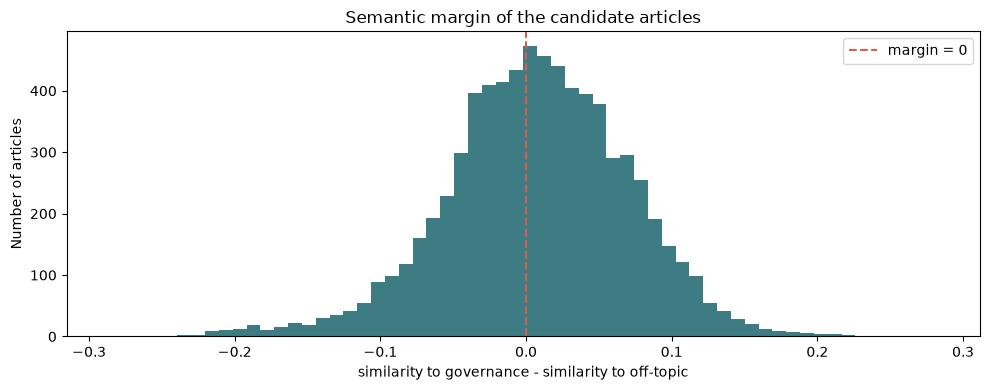


--- Q1 (lowest): margin -0.287 to -0.041 ---
-0.047  [industry_use   ] LumiQuant Academy Leads the Global Smart Trading Education Revolution with Quantyraxis AI, the 
-0.073  [market_report  ] OnlyFans in 2026: Is It Still Worth It for Gen Z Creators?
-0.195  [market_report  ] E-Learning Market Growth, Size, and Business Forecast 2026-2033
-0.046  [energy         ] New Smart Windows that are Self-Cleaning & Energy Efficient
-0.075  [industry_use   ] AI is Transforming Consumer Packaged Goods ( CPG): Are You Keeping Up?
-0.080  [market_report  ] Midyear update 2025 AI predictions: PwC
-0.062  [enterprise     ] Leona Health Raises $ 14M from a16z for WhatsApp AI Co-Pilot Aiding LatAm Doctors
-0.093  [market_report  ] KPMG Careers: Experienced Professionals

--- Q2: margin -0.040 to -0.007 ---
-0.033  [industry_use   ] Vendor Payment Automation
-0.026  [enterprise     ] Discussion with Professor Marina Jirotka, Human Centered Computing, University of Oxford
-0.011  [industry_use   ] Adva

gov_v2,False,True,All
in_stage1,,,
False,33759,1292,35051
True,9655,2738,12393
All,43414,4030,47444


In [13]:
cand = df[df["gov_lexical"]].copy()

# 1. Distribution of the semantic margin
plt.figure(figsize=(10, 4))
plt.hist(cand["sem_margin"], bins=60, color="#3D7C83")
plt.axvline(0, color="#D95D4F", linestyle="--", label="margin = 0")
plt.title("Semantic margin of the candidate articles")
plt.xlabel("similarity to governance - similarity to off-topic")
plt.ylabel("Number of articles")
plt.legend()
plt.tight_layout()
plt.show()

# 2. Random titles per margin quintile (from "clearly off-topic" to "clearly governance")
cand["margin_bin"] = pd.qcut(cand["sem_margin"], 5, labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"])
for bin_name, group in cand.groupby("margin_bin", observed=True):
    print(f"\n--- {bin_name}: margin {group['sem_margin'].min():.3f} to {group['sem_margin'].max():.3f} ---")
    for _, row in group.sample(n=8, random_state=RANDOM_STATE).iterrows():
        label = row["sem_gov_label"] if row["sem_margin"] > 0 else row["sem_off_label"]
        print(f"{row['sem_margin']:+.3f}  [{label:<15}] {str(row['title'])[:95]}")

# 3. Articles we discussed in the lexical step
CHECK_TITLES = ["Privacy notice", "Tesla Cybercab", "IoT on Manufacturing", "Laura Zommer",
                "SEO", "Copyright Office", "EU Fines Google", "AI safety amid Trump", "woke AI"]
print("\n--- Known examples ---")
for keyword in CHECK_TITLES:
    rows = cand[cand["title"].str.contains(keyword, regex=False, na=False)]
    for _, row in rows.head(2).iterrows():
        print(f"{row['sem_margin']:+.3f}  {str(row['title'])[:95]}")

# 4. Provisional combined filter: lexical candidate AND positive semantic margin
df["gov_v2"] = df["gov_lexical"] & (df["sem_margin"] > 0)
print(f"\nCandidates (lexical):      {df['gov_lexical'].sum():,}")
print(f"Lexical + semantic (> 0):  {df['gov_v2'].sum():,}")
display(pd.crosstab(df["in_stage1"], df["gov_v2"], margins=True))

### Results of the semantic score (Pascal)

The semantic margin separates the candidates roughly, but not sharply: its standard deviation is only 0.063. A random sample per quintile shows:

- **Q1–Q2 (margin below −0.007):** almost only off-topic articles, e.g. market reports, trading software, a KPMG careers page and healthcare applications. The *"Privacy notice"* page (−0.177) and the IoT manufacturing guide (−0.071) are correctly removed.
- **Q3 (around 0):** mixed. Funding rounds of compliance startups and articles about AGI or quantum partnerships appear next to real governance articles such as the DOJ antitrust case.
- **Q4–Q5:** mostly governance articles, e.g. caste bias in OpenAI models, the Reddit vs. Perplexity lawsuit, the Digital Markets Act, the US Copyright Office report and Trump's AI Action Plan.

With a threshold of 0, the combined filter keeps **4,030 articles**: 2,738 from the Stage 1 corpus and 1,292 new ones. Some false positives remain, e.g. *"Tesla Cybercab Prototypes Tested in Austin"* (+0.053) and articles about AI and SEO.

So far we set the threshold of 0 and the combination of the lexical and semantic scores by hand. In the next section we evaluate both on a manually annotated sample and choose the final filter based on measured precision and recall.

## 1.3 Splitting the articles into passages (Pascal)

The RAG system does not retrieve whole articles, but **passages**: our articles have a median of about 1,250 words, while embedding models can only read 512 tokens. Passages are also the unit for the relation extraction in section 1.4. Every relation in the knowledge graph therefore points to a passage that the RAG system can retrieve and cite. This makes the evidence of every relation traceable, which was a main problem of the Stage 1 extraction.

We split all **7,264 lexical candidates**, not only the final corpus. The final filter of section 1.2 can only remove candidates, so the final passages are a subset that we select later by `doc_id`.

**Text cleaning.** For RAG we use the original `content` and not `cleaned_text`: answers and entity names need upper and lower case and punctuation. We only apply light cleaning:

- repair wrong encodings with `ftfy` (e.g. *"Itâs"* → *"It's"*);
- remove HTML tags and URLs;
- remove spaces inside contractions (e.g. *"Office’ s"* → *"Office's"*), an artefact we found in many titles.

**Splitting.** We split the text into sentences with the spaCy `sentencizer` and combine consecutive sentences into passages of at most **180 words** (about 240 tokens). Neighbouring passages overlap by **one sentence**, so that information at a passage border is not lost.

**List format.** Some articles are stored as a Python list of paragraphs (`['First paragraph.', 'Second paragraph.']`). A first run left the separators `', '` inside the passages. We therefore convert these texts back into continuous text before splitting.

**Boilerplate.** In Stage 1 we found recurring source boilerplate (navigation texts, newsletter boxes, footers, job-posting templates). A first run that removed only identical *passages* missed boilerplate sentences inside otherwise relevant passages (e.g. *"Explore new launches, feature updates, and innovations from Rippling."*). We therefore remove boilerplate at the **sentence level**: a sentence that appears in **three or more articles of the same domain** is removed before the passages are built. We count per domain so that agency reports that several outlets publish are kept. Finally, we remove very short passages (under 25 words).

In [14]:

import ast
import html
import ftfy
from collections import Counter


def join_list_content(text):
    """Some articles are stored as a Python list of paragraphs: "['First.', 'Second.']"."""
    stripped = str(text).strip()
    if not (stripped.startswith("['") or stripped.startswith('["')):
        return text
    try:
        parts = ast.literal_eval(stripped)
        if isinstance(parts, list):
            return " ".join(str(p) for p in parts)
    except (ValueError, SyntaxError):
        pass
    # Fallback for lists that cannot be parsed (e.g. truncated texts)
    stripped = stripped.strip("[]")
    return re.sub(r"""['"]\s*,\s*['"]""", " ", stripped).strip("'\" ")


def clean_for_rag(text):
    """Light cleaning for RAG: keep case and punctuation, repair encoding errors."""
    if not isinstance(text, str):
        return ""
    text = join_list_content(text)
    text = ftfy.fix_text(text)                                       # "Itâs" -> "It's"
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)                            # HTML tags
    text = re.sub(r"https?://\S+", " ", text)                       # URLs
    text = re.sub(r"(['’])\s+(s|t|re|ve|ll|d|m)\b", r"\1\2", text)  # "Office’ s" -> "Office's"
    text = re.sub(r"\s+", " ", text).strip()
    return text


# Test 1: titles with encoding problems
test_titles = df.loc[df["title"].str.contains("â|’ s|’ t", regex=True, na=False), "title"].head(3)
for title in test_titles:
    print(f"before: {title[:90]}")
    print(f"after:  {clean_for_rag(title)[:90]}\n")

# Test 2: an article in list format
list_example = df.loc[df["content"].astype(str).str.startswith("['"), "content"].iloc[0]
print(f"before: {list_example[:200]}")
print(f"after:  {clean_for_rag(list_example)[:200]}")

before: Celebrating student entrepreneurship at delta v’ s 2024 Demo Day
after:  Celebrating student entrepreneurship at delta v's 2024 Demo Day

before: IBM’ s Quantum-Centric Supercomputing Vision Is Coming
after:  IBM's Quantum-Centric Supercomputing Vision Is Coming

before: Open-source imagery is transforming investigations of international crimes – but how do ju
after:  Open-source imagery is transforming investigations of international crimes – but how do ju

before: ['With the field of AI accelerating all the time, keeping track of the developments can prove difficult.', "Luckily, certain companies, who's core offerings are made up of AI products, can sometimes s
after:  With the field of AI accelerating all the time, keeping track of the developments can prove difficult. Luckily, certain companies, who's core offerings are made up of AI products, can sometimes serve 


In [15]:
import spacy

PASSAGES_FILE = os.path.join(STAGE3_FOLDER, "passages_candidates_v2.parquet")
MAX_PASSAGE_WORDS = 180
OVERLAP_SENTENCES = 1
MIN_PASSAGE_WORDS = 25
BOILERPLATE_MIN_DOCS = 3   # same sentence in >= 3 articles of the same domain

nlp_sent = spacy.blank("en")
nlp_sent.add_pipe("sentencizer")
nlp_sent.max_length = 2_000_000


def get_sentences(spacy_doc):
    """Sentences of a document; very long 'sentences' (e.g. lists) are cut into pieces."""
    sentences = []
    for sent in spacy_doc.sents:
        words = sent.text.split()
        for i in range(0, len(words), MAX_PASSAGE_WORDS):
            sentences.append(" ".join(words[i:i + MAX_PASSAGE_WORDS]))
    return sentences


def build_passages(sentences):
    """Combine consecutive sentences into passages of at most MAX_PASSAGE_WORDS words."""
    passages, start = [], 0
    while start < len(sentences):
        current, n_words, end = [], 0, start
        while end < len(sentences) and (
            not current or n_words + len(sentences[end].split()) <= MAX_PASSAGE_WORDS
        ):
            current.append(sentences[end])
            n_words += len(sentences[end].split())
            end += 1
        passages.append(" ".join(current))
        if end >= len(sentences):
            break
        start = max(end - OVERLAP_SENTENCES, start + 1)   # overlap of one sentence
    return passages


def sentence_key(sentence):
    return re.sub(r"\W+", " ", sentence.lower()).strip()


candidates = df[df["gov_lexical"]]

if os.path.exists(PASSAGES_FILE):
    passages = pd.read_parquet(PASSAGES_FILE)
    print("Loaded passages from cache.")
else:
    # 1. Clean and split into sentences
    texts = [clean_for_rag(c) for c in tqdm(candidates["content"], desc="cleaning")]
    titles = [clean_for_rag(t) for t in candidates["title"]]
    sentence_lists = [
        get_sentences(d) for d in tqdm(nlp_sent.pipe(texts, batch_size=50),
                                       total=len(texts), desc="sentences")
    ]

    # 2. In how many articles of the same domain does each sentence occur?
    docs_per_sentence = Counter()
    for domain, sentences in zip(candidates["domain"], sentence_lists):
        for key in {sentence_key(s) for s in sentences}:
            docs_per_sentence[(domain, key)] += 1
    boilerplate_keys = {k for k, n in docs_per_sentence.items() if n >= BOILERPLATE_MIN_DOCS}

    # 3. Remove boilerplate sentences and build the passages
    rows, n_sentences, n_removed = [], 0, 0
    for doc_id, title, date, domain, url, sentences in zip(
        candidates.index, titles, candidates["published_at"],
        candidates["domain"], candidates["url"], sentence_lists
    ):
        kept = [s for s in sentences if (domain, sentence_key(s)) not in boilerplate_keys]
        n_sentences += len(sentences)
        n_removed += len(sentences) - len(kept)
        for k, text in enumerate(build_passages(kept)):
            rows.append({
                "passage_id": f"{doc_id}_{k:03d}", "doc_id": doc_id, "chunk_index": k,
                "title": title, "published_at": date, "domain": domain, "url": url, "text": text,
            })

    passages = pd.DataFrame(rows)
    passages["n_words"] = passages["text"].str.split().str.len()
    n_raw = len(passages)
    passages = passages[passages["n_words"] >= MIN_PASSAGE_WORDS].reset_index(drop=True)
    passages.to_parquet(PASSAGES_FILE, index=False)

    print(f"Sentences:                    {n_sentences:>9,}")
    print(f"Removed boilerplate sentences: {n_removed:>8,} ({n_removed / n_sentences:.1%})")
    print(f"Passages:                     {n_raw:>9,}")
    print(f"Removed as too short:         {n_raw - len(passages):>9,}")
    print(f"Final passages:               {len(passages):>9,}")

    # Most frequent boilerplate sentences
    top_boilerplate = sorted(
        ((n, domain, key) for (domain, key), n in docs_per_sentence.items() if n >= BOILERPLATE_MIN_DOCS),
        reverse=True
    )[:12]
    print("\nMost frequent boilerplate sentences (domain, articles, text):")
    for n, domain, key in top_boilerplate:
        print(f"  {domain:<15} {n:>4}  {key[:90]}")

# Check: no list separators left
n_left = passages["text"].str.contains(r"""['"], ['"]""", regex=True).sum()
print(f"\nPassages with remaining list separators: {n_left:,}")

Loaded passages from cache.

Passages with remaining list separators: 177


,articles,passages,median_passages_per_article,median_words_per_passage,max_words_per_passage
0,7247,72576,8.0,168.0,180


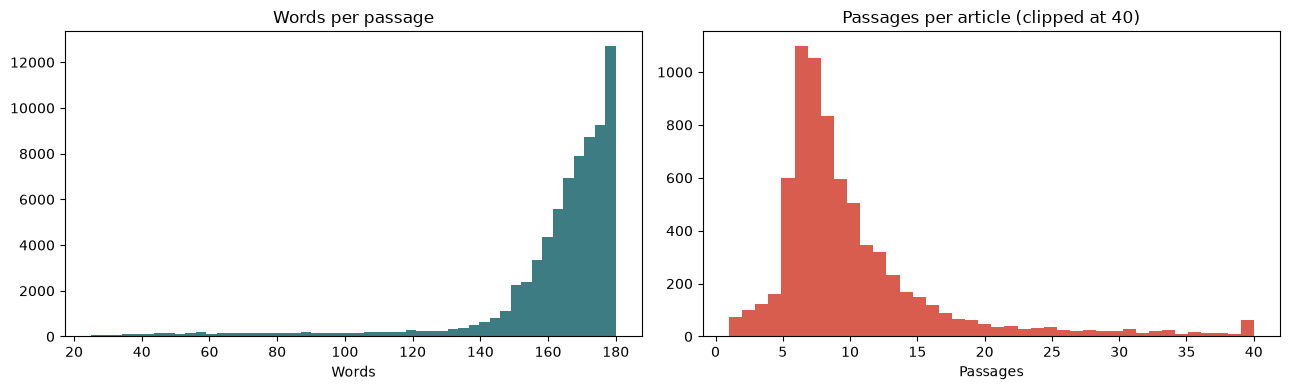

[20063_000] 2025-07-12 | Meta's Joel Kaplan: UK can lead in AI, if it avoids Brussels' failures
The UK is not alone in facing big economic challenges. Governments around the world are wrestling with vast
deficits, strains on public services, productivity crises and high prices. But crises can also be the jolt
that governments need to think and act big. The UK is better placed than most countries to establish itself as
a major AI power. It has a deep talent pool, world-leading universities and a long-standing culture of
innovation. But that won't count for much without strong political leadership. Sir Keir Starmer is certainly
talking the talk. He has called AI " the greatest force for change in the world right now " and laid out an
ambitious strategy to position the UK as an " AI maker, not an AI taker " by encouraging home-grown
innovation, investment in AI infrastructure and a transformation of the delivery of public services, such as
the NHS. 

[20063_001] 2025-07-12 | Meta's Joel K

In [16]:
passages_per_doc = passages.groupby("doc_id").size()

stats = pd.DataFrame({
    "articles": [passages["doc_id"].nunique()],
    "passages": [len(passages)],
    "median_passages_per_article": [passages_per_doc.median()],
    "median_words_per_passage": [passages["n_words"].median()],
    "max_words_per_passage": [passages["n_words"].max()],
})
display(stats)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.hist(passages["n_words"], bins=50, color="#3D7C83")
ax1.set_title("Words per passage")
ax1.set_xlabel("Words")
ax2.hist(passages_per_doc.clip(upper=40), bins=40, color="#D95D4F")
ax2.set_title("Passages per article (clipped at 40)")
ax2.set_xlabel("Passages")
plt.tight_layout()
plt.show()

# Example: the first three passages of one article
example_doc = passages["doc_id"].sample(1, random_state=RANDOM_STATE).iloc[0]
for _, row in passages[passages["doc_id"] == example_doc].head(3).iterrows():
    print(f"[{row['passage_id']}] {row['published_at']:%Y-%m-%d} | {row['title'][:70]}")
    print(textwrap.fill(row["text"], 110), "\n")

### Source check (Pascal)

The most frequent boilerplate passages come from a few sources: job postings on *builtin*, report templates on *skyquestt* and product text on *hiddenlayer*. In Stage 1 we already excluded *builtin*, *skyquestt* and *zbrain* from topic modeling, because they publish highly templated, non-journalistic content. These sources are still part of the RAG candidates, and removing the repeated passages does not change the character of these pages.

We therefore check the sources of the candidates: how many articles each domain contributes, how many of its passages were boilerplate, and how many of its texts are stored as a Python list (`['...`), which points to scraping artefacts.

In [17]:
STAGE1_EXCLUDED_DOMAINS = ["builtin", "skyquestt", "zbrain"]

candidates = df[df["gov_lexical"]]

domain_stats = candidates.groupby("domain").agg(
    articles=("title", "size"),
    list_format_share=("content", lambda s: s.astype(str).str.startswith("['").mean()),
)
domain_stats["passages"] = passages.groupby("domain").size()
domain_stats["passages_per_article"] = domain_stats["passages"] / domain_stats["articles"]
domain_stats = domain_stats.sort_values("articles", ascending=False)

print(f"Candidate articles: {len(candidates):,} from {len(domain_stats):,} domains\n")
print("Top 25 domains:")
display(domain_stats.head(25).round(2))

print("Domains excluded in Stage 1 (topic modeling):")
display(domain_stats.reindex(STAGE1_EXCLUDED_DOMAINS).round(2))

print("Domains with list-formatted content:")
display(domain_stats[domain_stats["list_format_share"] > 0.5].round(2))

# Random titles of the excluded and list-formatted sources
suspicious = STAGE1_EXCLUDED_DOMAINS + list(domain_stats[domain_stats["list_format_share"] > 0.5].index)
for domain in dict.fromkeys(suspicious):
    titles = candidates.loc[candidates["domain"] == domain, "title"]
    if len(titles) == 0:
        continue
    print(f"\n--- {domain} ({len(titles)} articles) ---")
    for title in titles.sample(n=min(5, len(titles)), random_state=RANDOM_STATE):
        print("  ", str(title)[:100])

Candidate articles: 7,264 from 288 domains

Top 25 domains:


,articles,list_format_share,passages,passages_per_article
domain,,,,
aijourn,476,1.00,3854,8.10
builtin,284,0.98,1911,6.73
kpmg,236,0.99,1768,7.49
theconversation,223,1.00,1603,7.19
skyquestt,189,0.97,2443,12.93
apnews,178,1.00,1754,9.85
zbrain,167,1.00,1312,7.86
ey,154,0.82,1571,10.20
aithority,151,1.00,1557,10.31


Domains excluded in Stage 1 (topic modeling):


,articles,list_format_share,passages,passages_per_article
domain,,,,
builtin,284,0.98,1911,6.73
skyquestt,189,0.97,2443,12.93
zbrain,167,1.00,1312,7.86


Domains with list-formatted content:


,articles,list_format_share,passages,passages_per_article
domain,,,,
aijourn,476,1.00,3854,8.10
builtin,284,0.98,1911,6.73
kpmg,236,0.99,1768,7.49
theconversation,223,1.00,1603,7.19
skyquestt,189,0.97,2443,12.93
...,...,...,...,...
invidis,1,1.00,6,6.00
hackster,1,1.00,44,44.00
greylock,1,1.00,12,12.00



--- builtin (284 articles) ---
   How to Overcome Algorithmic Confirmation Bias
   Engineering Manager, Switchboard - GitLab
   4 New Year’ s Resolutions The AI Industry Needs in 2026
   Senior Backend Engineer, SSCS: Pipeline Security - GitLab
   What Is xAI? The Company Behind Grok

--- skyquestt (189 articles) ---
   ESD Face Shield Market Size, Share
   Middle School Market Size, Share
   Enterprise Data Management Market Growth Drivers, Trends, and Opportunities
   Cloud Managed Service Market Size, Share, and Regional Growth Insights 2026-2033
   Endpoint Security Market Size, Share, and Regional Outlook 2026-2033

--- zbrain (167 articles) ---
   GDPR Compliance Monitoring Agent
   RFQ Broadcast AI Agent
   RFQ Creation Agent
   Procurement Contract Compliance Agent
   Treasury Compliance Monitoring Agent

--- aijourn (476 articles) ---
   How Human Security Teams and AI Agents Work Together in Modern Security Operations
   How AI is Advancing Network Management System Developm

### Source check (Pascal)

The most frequent boilerplate passages come from a few sources: job postings on *builtin*, report templates on *skyquestt* and product text on *hiddenlayer*. In Stage 1 we already excluded *builtin*, *skyquestt* and *zbrain* from topic modeling, because they publish highly templated, non-journalistic content. These sources are still part of the RAG candidates, and removing the repeated sentences does not change the character of these pages.

We therefore check the sources of the candidates: how many articles each domain contributes, how many passages per article remain, and how many of its texts are stored as a Python list (`['...`), which points to scraping artefacts.

In [18]:
STAGE1_EXCLUDED_DOMAINS = ["builtin", "skyquestt", "zbrain"]

candidates = df[df["gov_lexical"]]

domain_stats = candidates.groupby("domain").agg(
    articles=("title", "size"),
    list_format_share=("content", lambda s: s.astype(str).str.startswith("['").mean()),
)
domain_stats["passages"] = passages.groupby("domain").size()
domain_stats["passages_per_article"] = domain_stats["passages"] / domain_stats["articles"]
domain_stats = domain_stats.sort_values("articles", ascending=False)

print(f"Candidate articles: {len(candidates):,} from {len(domain_stats):,} domains\n")
print("Top 25 domains:")
display(domain_stats.head(25).round(2))

print("Domains excluded in Stage 1 (topic modeling):")
display(domain_stats.reindex(STAGE1_EXCLUDED_DOMAINS).round(2))

print("Domains with list-formatted content:")
display(domain_stats[domain_stats["list_format_share"] > 0.5].round(2))

# Random titles of the excluded and list-formatted sources
suspicious = STAGE1_EXCLUDED_DOMAINS + list(domain_stats[domain_stats["list_format_share"] > 0.5].index)
for domain in dict.fromkeys(suspicious):
    titles = candidates.loc[candidates["domain"] == domain, "title"]
    if len(titles) == 0:
        continue
    print(f"\n--- {domain} ({len(titles)} articles) ---")
    for title in titles.sample(n=min(5, len(titles)), random_state=RANDOM_STATE):
        print("  ", str(title)[:100])

Candidate articles: 7,264 from 288 domains

Top 25 domains:


,articles,list_format_share,passages,passages_per_article
domain,,,,
aijourn,476,1.00,3854,8.10
builtin,284,0.98,1911,6.73
kpmg,236,0.99,1768,7.49
theconversation,223,1.00,1603,7.19
skyquestt,189,0.97,2443,12.93
apnews,178,1.00,1754,9.85
zbrain,167,1.00,1312,7.86
ey,154,0.82,1571,10.20
aithority,151,1.00,1557,10.31


Domains excluded in Stage 1 (topic modeling):


,articles,list_format_share,passages,passages_per_article
domain,,,,
builtin,284,0.98,1911,6.73
skyquestt,189,0.97,2443,12.93
zbrain,167,1.00,1312,7.86


Domains with list-formatted content:


,articles,list_format_share,passages,passages_per_article
domain,,,,
aijourn,476,1.00,3854,8.10
builtin,284,0.98,1911,6.73
kpmg,236,0.99,1768,7.49
theconversation,223,1.00,1603,7.19
skyquestt,189,0.97,2443,12.93
...,...,...,...,...
invidis,1,1.00,6,6.00
hackster,1,1.00,44,44.00
greylock,1,1.00,12,12.00



--- builtin (284 articles) ---
   How to Overcome Algorithmic Confirmation Bias
   Engineering Manager, Switchboard - GitLab
   4 New Year’ s Resolutions The AI Industry Needs in 2026
   Senior Backend Engineer, SSCS: Pipeline Security - GitLab
   What Is xAI? The Company Behind Grok

--- skyquestt (189 articles) ---
   ESD Face Shield Market Size, Share
   Middle School Market Size, Share
   Enterprise Data Management Market Growth Drivers, Trends, and Opportunities
   Cloud Managed Service Market Size, Share, and Regional Growth Insights 2026-2033
   Endpoint Security Market Size, Share, and Regional Outlook 2026-2033

--- zbrain (167 articles) ---
   GDPR Compliance Monitoring Agent
   RFQ Broadcast AI Agent
   RFQ Creation Agent
   Procurement Contract Compliance Agent
   Treasury Compliance Monitoring Agent

--- aijourn (476 articles) ---
   How Human Security Teams and AI Agents Work Together in Modern Security Operations
   How AI is Advancing Network Management System Developm

In [19]:
remaining = passages[passages["text"].str.contains(r"""['"], ['"]""", regex=True)]
print(remaining["domain"].value_counts().head(5), "\n")
for _, row in remaining.sample(n=2, random_state=RANDOM_STATE).iterrows():
    match = re.search(r"""['"], ['"]""", row["text"])
    print(f"[{row['passage_id']}] ...{row['text'][max(0, match.start() - 120):match.end() + 120]}...\n")

domain
skyquestt         73
algorithmwatch    12
hbr                5
metro.co           5
dev                5
Name: count, dtype: int64 

[6076_002] ... craft a effective strategy, organisations must focus on a need for an " obsessive focus on results and sharp execution ", " value first " principles and " future cases " to enhance scalability and imagine new possibilities. Becky Power, Managi...

[16838_001] ...obtain, monitor or store all or any part of the content or Site, including whether manually or by way of any ' bot/robot', ' spider', ' scraper' or other automated software, device, algorithm, code, methodology, tool, process or similar technol...



### Source exclusions (Pascal)

The source check showed three groups of domains:

1. **Sources that are structurally not news articles:** job postings (*builtin*, e.g. "Senior Backend Engineer – GitLab"), market report templates (*skyquestt*), product pages of AI agents (*zbrain*) and model cards (*huggingface*, e.g. "microsoft/phi-4"). These pages describe no event and have no meaningful publication date, so they are not suitable evidence for a time-aware RAG system. We exclude these four domains completely. Three of them were already excluded from topic modeling in Stage 1.
2. **Mixed sources** such as consultancies (KPMG, EY, PwC) or vendor blogs publish both relevant and irrelevant articles. We do not exclude them by domain. The evaluated article-level filter of section 1.2 decides for each article.
3. **Specialised sources** that are valuable for our track, e.g. *hiddenlayer* (AI security research), *partnershiponai*, *algorithmwatch* or *ai-regulation*, are kept.

We also found that almost all articles in the dataset are stored as a Python list of paragraphs, not only a few sources. The conversion to continuous text in section 1.3 therefore affects the whole corpus.

In [20]:
EXCLUDED_DOMAINS = {
    "builtin":     "job postings and company profiles (also excluded in Stage 1)",
    "skyquestt":   "market report templates (also excluded in Stage 1)",
    "zbrain":      "product pages of AI agents (also excluded in Stage 1)",
    "huggingface": "model cards and dataset pages",
}

df["excluded_source"] = df["domain"].isin(EXCLUDED_DOMAINS)

excluded_overview = pd.DataFrame({
    "reason": EXCLUDED_DOMAINS,
    "candidate_articles": df[df["gov_lexical"]].groupby("domain").size().reindex(list(EXCLUDED_DOMAINS)),
    "passages": passages.groupby("domain").size().reindex(list(EXCLUDED_DOMAINS)),
}).fillna(0)
display(excluded_overview)

n_cand = df["gov_lexical"].sum()
n_cand_kept = (df["gov_lexical"] & ~df["excluded_source"]).sum()
n_pass_kept = (~passages["domain"].isin(EXCLUDED_DOMAINS)).sum()
print(f"Candidate articles: {n_cand:,} -> {n_cand_kept:,} after source exclusion")
print(f"Passages:           {len(passages):,} -> {n_pass_kept:,} after source exclusion")

# The passage file stays complete; the exclusion is applied together with
# the final topic filter of section 1.2 when we select the final corpus.

,reason,candidate_articles,passages
builtin,job postings and company profiles (also exclud...,284,1911
skyquestt,market report templates (also excluded in Stag...,189,2443
zbrain,product pages of AI agents (also excluded in S...,167,1312
huggingface,model cards and dataset pages,57,433


Candidate articles: 7,264 -> 6,567 after source exclusion
Passages:           72,576 -> 66,477 after source exclusion


## 1.4 Reproducible relation extraction with a controlled predicate schema (Gaël)

In Stage 1, LangExtract with `gemma3:4b` produced 998 relations with **421 distinct predicates**. Only 17 of 30 checked relations matched their source offsets, and after schema filtering only 29 relations remained. The Stage 1 feedback asked us to make the extraction **reproducible with a smaller, controlled predicate schema**. We changed four things:

1. **Smaller schema focused on governance.** The Stage 1 schema contained 8 entity types and general technology relations (e.g. `DEVELOPS`, `PARTNERS_WITH`). The new schema has **5 entity types and 9 predicates**. Every predicate describes a governance action and has a fixed **type signature** (allowed subject and object types).
2. **Schema enforced during generation.** The schema is not only described in the prompt: we pass it as a JSON schema to the model, which can then only generate predicates, entity types and type combinations of our schema.
3. **Passages as the extraction unit.** We extract from the passages of section 1.3, the same unit the RAG system retrieves. Every relation contains its `passage_id` and a **verbatim evidence quote**, which we check against the passage text.
4. **Reproducibility.** We use an open model with a recorded version, temperature 0 and a fixed seed. Every response is cached, so a second run gives exactly the same result.

### Schema definition (Gaël)

**Entity types**

| Type | Description | Examples |
|---|---|---|
| `LEGAL_INSTRUMENT` | Law, bill, regulation, executive order, code of practice, standard or official framework | EU AI Act, SB 53, GPAI Code of Practice, NIST AI RMF |
| `PUBLIC_AUTHORITY` | Government, legislature, regulator, agency, court or international organisation | European Commission, FTC, US Congress, Ofcom, UN |
| `ORGANIZATION` | Company, AI lab, NGO, publisher or industry association | OpenAI, Meta, The New York Times |
| `AI_SYSTEM` | Named AI model or AI product | ChatGPT, Grok, Claude, Llama |
| `PERSON` | Named individual | Gavin Newsom, Henna Virkkunen |

**Predicates**

| Predicate | Subject → Object | Meaning |
|---|---|---|
| `PROPOSES` | PUBLIC_AUTHORITY, PERSON → LEGAL_INSTRUMENT | drafts, introduces or proposes |
| `ADOPTS` | PUBLIC_AUTHORITY, PERSON → LEGAL_INSTRUMENT | passes, enacts, signs into law, formally publishes |
| `ENFORCES` | PUBLIC_AUTHORITY → LEGAL_INSTRUMENT | is responsible for or applies the enforcement of |
| `APPLIES_TO` | LEGAL_INSTRUMENT → ORGANIZATION, AI_SYSTEM | imposes obligations on, covers |
| `INVESTIGATES_OR_SANCTIONS` | PUBLIC_AUTHORITY → ORGANIZATION, AI_SYSTEM | investigates, fines, bans or orders |
| `SUES` | ORGANIZATION, PERSON, PUBLIC_AUTHORITY → ORGANIZATION | files a lawsuit against |
| `COMPLIES_WITH` | ORGANIZATION → LEGAL_INSTRUMENT | signs, commits to or complies with |
| `SUPPORTS` | ORGANIZATION, PERSON, PUBLIC_AUTHORITY → LEGAL_INSTRUMENT | publicly endorses or lobbies for |
| `OPPOSES` | ORGANIZATION, PERSON, PUBLIC_AUTHORITY → LEGAL_INSTRUMENT | criticises, refuses, vetoes, challenges or lobbies against |

Every relation also has a **modality**: `actual` (it happened) or `planned` (announced or intended). For questions such as "When did the EU adopt the AI Act?", it matters whether something was done or only announced.

In [21]:
L, A, O, S, P = "LEGAL_INSTRUMENT", "PUBLIC_AUTHORITY", "ORGANIZATION", "AI_SYSTEM", "PERSON"

KG_SCHEMA = {
    "version": "stage3_v1",
    "entity_types": {
        L: "Law, bill, regulation, executive order, code of practice, standard or official framework",
        A: "Government, legislature, regulator, agency, court or international organisation",
        O: "Company, AI lab, NGO, publisher or industry association",
        S: "Named AI model or AI product",
        P: "Named individual",
    },
    "predicates": {
        "PROPOSES":                  {"subject": [A, P],    "object": [L],    "meaning": "drafts, introduces or proposes"},
        "ADOPTS":                    {"subject": [A, P],    "object": [L],    "meaning": "passes, enacts, signs into law, formally publishes"},
        "ENFORCES":                  {"subject": [A],       "object": [L],    "meaning": "is responsible for or applies the enforcement of"},
        "APPLIES_TO":                {"subject": [L],       "object": [O, S], "meaning": "imposes obligations on, covers"},
        "INVESTIGATES_OR_SANCTIONS": {"subject": [A],       "object": [O, S], "meaning": "investigates, fines, bans or orders"},
        "SUES":                      {"subject": [O, P, A], "object": [O],    "meaning": "files a lawsuit against"},
        "COMPLIES_WITH":             {"subject": [O],       "object": [L],    "meaning": "signs, commits to or complies with"},
        "SUPPORTS":                  {"subject": [O, P, A], "object": [L],    "meaning": "publicly endorses or lobbies for"},
        "OPPOSES":                   {"subject": [O, P, A], "object": [L],    "meaning": "criticises, refuses, vetoes, challenges or lobbies against"},
    },
    "modalities": ["actual", "planned"],
}

ENTITY_TYPES = list(KG_SCHEMA["entity_types"])
PREDICATES = list(KG_SCHEMA["predicates"])

# Save the schema as part of our data dictionary
SCHEMA_FILE = os.path.join(STAGE3_FOLDER, "kg_schema_stage3.json")
with open(SCHEMA_FILE, "w", encoding="utf-8") as f:
    json.dump(KG_SCHEMA, f, indent=2)

print(f"{len(ENTITY_TYPES)} entity types, {len(PREDICATES)} predicates -> saved to {SCHEMA_FILE}")
pd.DataFrame([
    {"predicate": p, "subject": " | ".join(v["subject"]), "object": " | ".join(v["object"]), "meaning": v["meaning"]}
    for p, v in KG_SCHEMA["predicates"].items()
])

5 entity types, 9 predicates -> saved to /Users/pascalingold/Library/CloudStorage/GoogleDrive-pascal.mscids@gmail.com/My Drive/NLP_Projekt/stage3/kg_schema_stage3.json


,predicate,subject,object,meaning
0,PROPOSES,PUBLIC_AUTHORITY | PERSON,LEGAL_INSTRUMENT,"drafts, introduces or proposes"
1,ADOPTS,PUBLIC_AUTHORITY | PERSON,LEGAL_INSTRUMENT,"passes, enacts, signs into law, formally publi..."
2,ENFORCES,PUBLIC_AUTHORITY,LEGAL_INSTRUMENT,is responsible for or applies the enforcement of
3,APPLIES_TO,LEGAL_INSTRUMENT,ORGANIZATION | AI_SYSTEM,"imposes obligations on, covers"
4,INVESTIGATES_OR_SANCTIONS,PUBLIC_AUTHORITY,ORGANIZATION | AI_SYSTEM,"investigates, fines, bans or orders"
5,SUES,ORGANIZATION | PERSON | PUBLIC_AUTHORITY,ORGANIZATION,files a lawsuit against
6,COMPLIES_WITH,ORGANIZATION,LEGAL_INSTRUMENT,"signs, commits to or complies with"
7,SUPPORTS,ORGANIZATION | PERSON | PUBLIC_AUTHORITY,LEGAL_INSTRUMENT,publicly endorses or lobbies for
8,OPPOSES,ORGANIZATION | PERSON | PUBLIC_AUTHORITY,LEGAL_INSTRUMENT,"criticises, refuses, vetoes, challenges or lob..."


### Selection of passages for extraction (Gaël)

Most passages contain no governance relation at all, e.g. introductions or background explanations. Sending them to the LLM would only cost time. We therefore pre-select passages with three simple rules:

1. The article is in the **provisional governance corpus** (lexical candidate, positive semantic margin, not an excluded source). Relations of articles that the final filter of section 1.2 removes are dropped later.
2. The passage mentions at least one **legal instrument** (e.g. "... Act", "Executive Order", "Code of Practice", "SB 53") **and** at least one **public authority or organisation** (e.g. "Commission", "FTC", "Congress", "court", or a known AI company).
3. The passage contains a **trigger verb** for one of our predicates (e.g. *passed, signed, proposed, fined, sued, comply, oppose*).

From the eligible passages we draw **25 per month** (about 600 for 24 months) with a fixed random seed. This way the extraction covers the whole observation period and is not dominated by the peak months. Stage 1 used the same principle with 25 articles per month.

In [22]:
PASSAGES_PER_MONTH = 25

# 1. Legal instruments: generic patterns (case-sensitive, the text keeps its upper case)
LEGAL_PATTERN = re.compile(
    r"\b(?:[A-Z][\w.'-]*\s){0,5}(?:Act|Bill|Directive|Regulation|Executive Order|Code of Practice|"
    r"Framework|Convention|Treaty|Action Plan)\b"
    r"|\b(?:SB|AB|HB|S\.|H\.R\.)\s?\d{1,5}\b"
    r"|\b(?:GDPR|DSA|DMA|AI Act|NIST AI RMF|ISO/IEC 42001|ISO 42001)\b"
)

# 2. Public authorities and organisations
ACTOR_PATTERN = re.compile(
    r"\b(?:Commission|Parliament|Council|Congress|Senate|House|White House|Administration|Government|"
    r"Ministry|Department|Agency|Authority|Regulator|Court|Judge|Attorney General|Governor|President|"
    r"FTC|SEC|FCC|DOJ|NIST|CAISI|Ofcom|CNIL|Garante|ICO|AI Office|AI (?:Safety|Security) Institute|"
    r"United Nations|OECD|UNESCO|G7|"
    r"OpenAI|Anthropic|Google|DeepMind|Meta|Microsoft|Apple|Amazon|Nvidia|xAI|Mistral|DeepSeek|"
    r"TikTok|ByteDance|IBM|Perplexity|Stability AI|Midjourney|Character\.AI)\b"
)

# 3. Trigger verbs for our predicates
TRIGGER_PATTERN = re.compile(
    r"\b(?:propos\w*|introduc\w*|draft\w*|pass(?:ed|es)?|adopt\w*|enact\w*|sign(?:ed|s|ing)?|approv\w*|"
    r"publish\w*|enforc\w*|appl(?:y|ies|ied)|fin(?:ed|es)|investigat\w*|prob(?:e|ed|es|ing)|ban(?:s|ned)?|"
    r"order(?:ed|s)?|su(?:e|ed|es|ing)|lawsuit|compl(?:y|ies|ied|iance)|commit\w*|endors\w*|back(?:ed|s)?|"
    r"support\w*|oppos\w*|criticiz\w*|criticis\w*|challeng\w*|lobb\w*|veto\w*|block\w*)\b",
    re.IGNORECASE,
)

# Provisional governance corpus (final corpus is chosen in section 1.2)
provisional_docs = df.index[df["gov_v2"] & ~df["excluded_source"]]
pool = passages[passages["doc_id"].isin(provisional_docs)].copy()

pool["n_legal"] = pool["text"].str.count(LEGAL_PATTERN)
pool["n_actor"] = pool["text"].str.count(ACTOR_PATTERN)
pool["has_trigger"] = pool["text"].str.contains(TRIGGER_PATTERN)
pool["eligible"] = (pool["n_legal"] >= 1) & (pool["n_actor"] >= 1) & pool["has_trigger"]
pool["month"] = pool["published_at"].dt.to_period("M").astype(str)

eligible = pool[pool["eligible"]]
print(f"Passages of the provisional corpus: {len(pool):,}")
print(f"Eligible for extraction:            {len(eligible):,} ({len(eligible) / len(pool):.1%})")

# 25 passages per month, reproducible: shuffle once, then take the first 25 per month
extraction_set = (
    eligible.sample(frac=1, random_state=RANDOM_STATE)
    .groupby("month")
    .head(PASSAGES_PER_MONTH)
    .sort_values("passage_id")
    .reset_index(drop=True)
)
print(f"Selected for extraction:            {len(extraction_set):,} passages "
      f"from {extraction_set['doc_id'].nunique():,} articles\n")

display(extraction_set.groupby("month").size().rename("passages").to_frame().T)

# Two examples
for _, row in extraction_set.sample(n=2, random_state=RANDOM_STATE).iterrows():
    print(f"\n[{row['passage_id']}] {row['published_at']:%Y-%m-%d} | {row['title'][:80]}")
    print(textwrap.fill(row["text"], 110))

Passages of the provisional corpus: 37,786
Eligible for extraction:            1,670 (4.4%)
Selected for extraction:            598 passages from 417 articles



month,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,...,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
passages,23,25,25,25,25,25,25,25,25,25,...,25,25,25,25,25,25,25,25,25,25



[1815_000] 2024-10-14 | Breaking Down the Arguments for and against U.S. Antitrust Legislation
In many areas of the world, including the European Union, United Kingdom, South Korea, and Australia,
governments are considering new legislation to check the market power of a few dominant technology platforms.
Yet some of the most sweeping proposals are taking place within the U.S. Congress. In October 2020, the
majority staff of the House Subcommittee on Antitrust, Commercial, and Administrative Law published a set of
recommendations to promote competition in technology markets, the result of a 16-month investigation that
directed attention to the actions of Alphabet ( the parent company of Google), Amazon, Apple, and Facebook (
now Meta). The House Judiciary Committee advanced six bills in June 2021 that paralleled many of these
recommendations, focusing on the anticompetitive impacts of self-preferencing, mergers and acquisitions, data
accumulation, and network effects related to digita

### Extraction with an open model and an enforced JSON schema (Gaël)

**Why not the Gemini API?** We first tested the free tier of the Gemini API. It was not usable for this task: the daily request limit was reached after a few requests, and many requests failed because of server overload (error 503). In Stage 1 the token limit had also been reached immediately. We therefore run an **open model locally on the Colab GPU** with **Ollama**. This has two further advantages: there are no rate limits, and the exact model version (the Ollama *digest*) can be recorded, so nobody can replace the model behind a name.

**Model.** We use **Qwen3** (4-bit quantised) on a T4 GPU, with the "thinking" mode switched off. Qwen3 is one of the compact open model families of Stage 2. In Stage 1 we used `gemma3:4b`, which did not follow the schema.

**Enforced schema.** We pass our response schema as a JSON schema to Ollama (`format=`). Ollama restricts the generation to this schema:

- The schema contains **one variant per predicate** with only its allowed subject and object types. Invalid type combinations, e.g. a law as the object of `INVESTIGATES_OR_SANCTIONS`, cannot be generated.
- The **order of the fields** is the order of generation. The model first copies the **evidence** sentence, then determines **subject, object and their types**, and only then the **predicate**. At this point the schema only allows predicates that fit the chosen types. Copying the evidence first makes the model derive the relation from the text instead of inventing it.
- The schema allows at most 20 relations per batch and 300 characters per evidence quote.

**Prompt.** We send the passages in **batches of 10**. The prompt contains the entity types, the predicates with their type signatures, our extraction rules and **three invented examples** (a fictional country, company and politicians): relations of an authority, a person and a company, a passage **without** any relation, and a veto. We do not use passages from our corpus as examples, so that the examples do not leak into the results.

**Reproducibility.** Temperature 0, a fixed seed, a fixed prompt version and the recorded model digest. Every response is cached on Google Drive. The cache key contains the model, its digest, the prompt version and the passage texts, so every change automatically leads to a new extraction.

**Development of the prompt.** We tested every version on the same batch of 10 passages:

- **v1** (simple schema, one example): `qwen3:8b` extracted more than 40 relations from 10 passages. The answer was cut off, and many relations were wrong, e.g. *Gavin Newsom ENFORCES SB 1047* (he vetoed it) or *Trump administration INVESTIGATES_OR_SANCTIONS Digital Services Act* (the object of this predicate must be an organisation).
- **v2** (one variant per predicate, length limits, negative example): 2 relations. When the model chose a wrong predicate first, the schema forced it to choose a wrong type as well (*SB 1047* was typed as an organisation).
- **v3** (types before predicate, examples for a person and a veto, names without titles): 3 relations with correct types, e.g. *Gavin Newsom OPPOSES Safe and Secure Innovation for Frontier AI Models Act*.

**Choice of the model.** We compared `qwen3:8b` and `qwen3:14b` with prompt v3 on the same test batch. Both found 3 relations. Both found *Gavin Newsom OPPOSES Senate Bill 1047* and the borderline case *Trump administration OPPOSES Digital Services Act*. The third relation of `qwen3:8b` (*EU Commission PROPOSES Digital Services Act*) was acceptable. The third relation of `qwen3:14b` had an unnamed group as subject (*"U.S. politicians"*). The test is too small to show a clear difference, and both models missed a criticism of the AI Act by a Meta manager. We use `qwen3:14b`: larger models usually follow instructions more reliably across many different passages, and the longer runtime (about 70 instead of 35 minutes) is needed only once because of the cache. Relations with generic names are removed by an additional automatic check.

In [23]:
import shutil
import subprocess

# In Colab: install Ollama. Locally: install the Ollama app from https://ollama.com/download
if IN_COLAB and shutil.which("ollama") is None:
    !apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh > /dev/null 2>&1

import ollama

OLLAMA_LOG_FILE = os.path.join(DATA_FOLDER, "ollama_server.log")


def ollama_running():
    try:
        ollama.list()
        return True
    except Exception:
        return False


def start_ollama_server():
    """Start the Ollama server in the background; its log is written to OLLAMA_LOG_FILE."""
    if shutil.which("ollama") is None:
        raise RuntimeError("Ollama is not installed: https://ollama.com/download")
    log = open(OLLAMA_LOG_FILE, "a")
    subprocess.Popen(["ollama", "serve"], stdout=log, stderr=subprocess.STDOUT)
    for _ in range(30):
        if ollama_running():
            return True
        time.sleep(1)
    return False


if not ollama_running():      # locally, the Ollama app usually runs already
    start_ollama_server()

print("Ollama server running:", ollama_running())

Ollama server running: True


In [24]:
EXTRACTION_MODEL = "qwen3:14b"   # comparison test; alternative: "qwen3:8b"

# Download the model and show the progress
last_status, last_percent = None, -10
for progress in ollama.pull(EXTRACTION_MODEL, stream=True):
    if progress.total and progress.completed:
        percent = 100 * progress.completed / progress.total
        if progress.status != last_status or percent - last_percent >= 10:
            print(f"{progress.status[:40]:<40} {percent:5.0f}%")
            last_status, last_percent = progress.status, percent
    elif progress.status != last_status:
        print(progress.status)
        last_status, last_percent = progress.status, -10

# Exact model version, so the extraction can be reproduced with the same weights
model_digest = next(m.digest for m in ollama.list().models if m.model == EXTRACTION_MODEL)
print(f"\nModel: {EXTRACTION_MODEL} | digest: {model_digest[:12]}")
print("Device:", DEVICE)

pulling manifest
pulling a8cc1361f314
pulling a8cc1361f314                         0%
pulling a8cc1361f314                        10%
pulling a8cc1361f314                        20%
pulling a8cc1361f314                        30%
pulling a8cc1361f314                        40%
pulling a8cc1361f314                        50%
pulling a8cc1361f314                        60%
pulling a8cc1361f314                        70%
pulling a8cc1361f314                        80%
pulling a8cc1361f314                        90%
pulling ae370d884f10
pulling d18a5cc71b84
pulling cff3f395ef37
pulling 78b3b822087d                       100%
verifying sha256 digest
writing manifest
success

Model: qwen3:14b | digest: bdbd181c33f2
Device: mps


In [25]:
from typing import Annotated, List, Literal, Union
from pydantic import BaseModel, Field, create_model

PROMPT_VERSION = "v3"
BATCH_SIZE = 10
MAX_RELATIONS_PER_BATCH = 20

ModalityLiteral = Literal[tuple(KG_SCHEMA["modalities"])]
ShortName = Annotated[str, Field(max_length=80)]
Evidence = Annotated[str, Field(max_length=300)]

# One relation model per predicate, with only the allowed subject and object types.
# Order of the fields = order of generation:
#   1. evidence (the model copies the sentence first),
#   2. subject, object and their types (easy to recognise),
#   3. predicate: the schema only allows predicates that fit the chosen types.
relation_models = []
for predicate, spec in KG_SCHEMA["predicates"].items():
    relation_models.append(create_model(
        f"Relation_{predicate}",
        passage_id=(str, ...),
        evidence=(Evidence, ...),
        subject=(ShortName, ...),
        subject_type=(Literal[tuple(spec["subject"])], ...),
        object=(ShortName, ...),
        object_type=(Literal[tuple(spec["object"])], ...),
        predicate=(Literal[predicate], ...),
        modality=(ModalityLiteral, ...),
    ))


class ExtractionResult(BaseModel):
    relations: Annotated[List[Union[tuple(relation_models)]], Field(max_length=MAX_RELATIONS_PER_BATCH)]


RESPONSE_SCHEMA = ExtractionResult.model_json_schema()

# Prompt
entity_type_lines = "\n".join(f"- {t}: {d}" for t, d in KG_SCHEMA["entity_types"].items())
predicate_lines = "\n".join(
    f"- {p}: {' | '.join(v['subject'])} -> {' | '.join(v['object'])} ({v['meaning']})"
    for p, v in KG_SCHEMA["predicates"].items()
)

EXAMPLE_PASSAGES = (
    "[EX_1] (published 2025-03-04) The Freedonian Parliament passed the Robot Liability Act on Monday, "
    "and Prime Minister Jane Doe signed it into law on Friday. Acme AI said it would challenge the law "
    "in court. The Freedonian Data Authority also fined Acme AI 2 million euros over its chatbot Acmebot.\n\n"
    "[EX_2] (published 2025-05-10) Critics say the Robot Liability Act could slow innovation. "
    "The act would have required audits for large models, and regulators would have enforced it.\n\n"
    "[EX_3] (published 2025-09-30) Governor Tom Roe of Westland vetoed the Drone Privacy Bill on Sunday."
)
EXAMPLE_OUTPUT = json.dumps({"relations": [
    {"passage_id": "EX_1", "evidence": "The Freedonian Parliament passed the Robot Liability Act on Monday",
     "subject": "Freedonian Parliament", "subject_type": "PUBLIC_AUTHORITY",
     "object": "Robot Liability Act", "object_type": "LEGAL_INSTRUMENT",
     "predicate": "ADOPTS", "modality": "actual"},
    {"passage_id": "EX_1", "evidence": "Prime Minister Jane Doe signed it into law on Friday",
     "subject": "Jane Doe", "subject_type": "PERSON",
     "object": "Robot Liability Act", "object_type": "LEGAL_INSTRUMENT",
     "predicate": "ADOPTS", "modality": "actual"},
    {"passage_id": "EX_1", "evidence": "Acme AI said it would challenge the law in court.",
     "subject": "Acme AI", "subject_type": "ORGANIZATION",
     "object": "Robot Liability Act", "object_type": "LEGAL_INSTRUMENT",
     "predicate": "OPPOSES", "modality": "planned"},
    {"passage_id": "EX_1", "evidence": "The Freedonian Data Authority also fined Acme AI 2 million euros",
     "subject": "Freedonian Data Authority", "subject_type": "PUBLIC_AUTHORITY",
     "object": "Acme AI", "object_type": "ORGANIZATION",
     "predicate": "INVESTIGATES_OR_SANCTIONS", "modality": "actual"},
    {"passage_id": "EX_3", "evidence": "Governor Tom Roe of Westland vetoed the Drone Privacy Bill on Sunday.",
     "subject": "Tom Roe", "subject_type": "PERSON",
     "object": "Drone Privacy Bill", "object_type": "LEGAL_INSTRUMENT",
     "predicate": "OPPOSES", "modality": "actual"},
]})

PROMPT_TEMPLATE = f"""You extract AI-governance relations from news passages.

Entity types:
{entity_type_lines}

Predicates (allowed subject types -> allowed object types):
{predicate_lines}

Rules:
1. Extract a relation only if a sentence states that a named actor DID or WILL DO the action.
   Do not use background knowledge.
2. Do NOT extract: what a law would do or could do, opinions of unnamed groups ("critics", "experts"),
   descriptions of how institutions work in general, or recommendations of the author.
3. subject and object must be specific named entities. Write names without titles or job descriptions
   ("Gavin Newsom", not "California Governor Gavin Newsom"). If the passage says "the law" or
   "the company", use the name it refers to in the same passage.
4. A named person (e.g. a governor, president, minister or manager) is a PERSON, not a PUBLIC_AUTHORITY.
   A law, bill or regulation is always a LEGAL_INSTRUMENT.
5. evidence: copy the ONE shortest sentence or clause that states the relation, word for word.
6. modality: "actual" if it already happened, "planned" if it is announced, intended or expected.
7. Many passages contain no relation. Extract at most 3 relations per passage.

Example (EX_2 contains no relation):
{EXAMPLE_PASSAGES}
Output:
{EXAMPLE_OUTPUT}

Passages:
{{passages}}

Answer only with JSON in the format of the example.
"""


def build_prompt(batch):
    passage_lines = "\n\n".join(
        f"[{row.passage_id}] (published {row.published_at:%Y-%m-%d}) {row.text}"
        for row in batch.itertuples()
    )
    return PROMPT_TEMPLATE.replace("{passages}", passage_lines)


def batch_key(batch):
    content = json.dumps([EXTRACTION_MODEL, model_digest, PROMPT_VERSION,
                          list(batch["passage_id"]), list(batch["text"])])
    return hashlib.md5(content.encode()).hexdigest()


batches = [extraction_set.iloc[i:i + BATCH_SIZE] for i in range(0, len(extraction_set), BATCH_SIZE)]
print(f"{len(extraction_set)} passages -> {len(batches)} batches of up to {BATCH_SIZE}")

598 passages -> 60 batches of up to 10


In [26]:
EXTEND_EXTRACTION = True

if EXTEND_EXTRACTION:
    # Additional passages: all eligible passages that are not in the first sample
    extra_set = (
        eligible[~eligible["passage_id"].isin(extraction_set["passage_id"])]
        .sort_values("passage_id")
        .reset_index(drop=True)
    )
    extra_batches = [extra_set.iloc[i:i + BATCH_SIZE] for i in range(0, len(extra_set), BATCH_SIZE)]

    # The first batches stay identical -> their answers come from the cache
    batches = batches + extra_batches
    extraction_set = pd.concat([extraction_set, extra_set], ignore_index=True)

print(f"Passages for extraction: {len(extraction_set):,} in {len(batches)} batches")

Passages for extraction: 1,670 in 168 batches


In [27]:
EXTRACTION_CACHE_FILE = os.path.join(STAGE3_FOLDER, "extraction_cache_ollama.jsonl")
MAX_BATCHES = None     # None = all batches; 1 = test mode
MAX_ATTEMPTS = 3

OLLAMA_OPTIONS = {
    "temperature": 0,
    "seed": RANDOM_STATE,
    "num_ctx": 8192,       # enough for the prompt with 10 passages
    "num_predict": 4096,   # maximum length of the answer
}


def load_extraction_cache():
    cache = {}
    if os.path.exists(EXTRACTION_CACHE_FILE):
        with open(EXTRACTION_CACHE_FILE, encoding="utf-8") as f:
            for line in f:
                record = json.loads(line)
                cache[record["batch_key"]] = record
    return cache


def request_batch(batch):
    response = ollama.chat(
        model=EXTRACTION_MODEL,
        messages=[{"role": "user", "content": build_prompt(batch)}],
        format=RESPONSE_SCHEMA,
        think=False,           # Qwen3: no reasoning tokens, only the JSON answer
        options=OLLAMA_OPTIONS,
    )
    return response.message.content


def request_with_retry(batch):
    """If the model runner crashes (e.g. GPU memory), Ollama restarts it with the next request."""
    for attempt in range(1, MAX_ATTEMPTS + 1):
        try:
            return request_batch(batch)
        except (ollama.ResponseError, ConnectionError) as e:
            print(f"  attempt {attempt}/{MAX_ATTEMPTS} failed: {str(e)[:100]}")
            if not ollama_running():
                start_ollama_server()
            time.sleep(15)
    return None


extraction_cache = load_extraction_cache()
todo = [b for b in batches if batch_key(b) not in extraction_cache]
n_cached = len(batches) - len(todo)
if MAX_BATCHES is not None:
    todo = todo[:MAX_BATCHES]
print(f"Batches: {len(batches)} | cached: {n_cached} | to process now: {len(todo)}")

failed_batches = []
for batch in tqdm(todo, desc="extraction"):
    raw = request_with_retry(batch)
    if raw is None:
        failed_batches.append(batch["passage_id"].iloc[0])
        continue
    record = {
        "batch_key": batch_key(batch), "model": EXTRACTION_MODEL, "model_digest": model_digest,
        "prompt_version": PROMPT_VERSION, "passage_ids": list(batch["passage_id"]), "response": raw,
    }
    with open(EXTRACTION_CACHE_FILE, "a", encoding="utf-8") as f:
        f.write(json.dumps(record) + "\n")
    extraction_cache[record["batch_key"]] = record

if failed_batches:
    print(f"\n{len(failed_batches)} batches failed (first passage: {failed_batches}). "
          "Run the cell again to retry them.")

# Flatten all cached responses of the current batches into one table
rows, n_invalid = [], 0
for batch in batches:
    record = extraction_cache.get(batch_key(batch))
    if record is None:
        continue
    try:
        rows.extend(json.loads(record["response"]).get("relations", []))
    except json.JSONDecodeError:
        n_invalid += 1   # e.g. answer cut off at num_predict

relations_raw = pd.DataFrame(rows)
print(f"\nBatches done: {sum(batch_key(b) in extraction_cache for b in batches)} / {len(batches)}")
print(f"Invalid JSON answers: {n_invalid}")
print(f"Raw relations: {len(relations_raw)}")
for m in ollama.ps().models:
    print(f"{m.model}: {m.size_vram / 1e9:.1f} GB on the GPU")

Batches: 168 | cached: 96 | to process now: 72


extraction:   0%|          | 0/72 [00:00<?, ?it/s]


Batches done: 168 / 168
Invalid JSON answers: 0
Raw relations: 720
qwen3:14b: 10.3 GB on the GPU


### Automatic checks of the extracted relations (Gaël)

The JSON schema guarantees valid predicates, entity types and type signatures, but not that a relation is supported by its passage. We therefore check every relation automatically:

1. **Known passage:** the `passage_id` must belong to the passages sent to the model.
2. **Evidence found:** the evidence quote must appear in the passage, word for word. We compare lowercase texts without punctuation and allow small differences (fuzzy match ≥ 90).
3. **Arguments grounded:** subject and object must appear in the passage (fuzzy match ≥ 90). This catches entities that the model adds from background knowledge.
4. **Valid type signature:** a second check of the schema rule (it should always pass).
5. **Specific names:** subject and object must not be generic groups such as "U.S. politicians", "lawmakers" or "tech companies". The prompt forbids them, but the model still returned one in a test.

Only relations that pass all five checks are kept for the knowledge graph. In section 1.5 we then validate the important relations against their passages.

In [28]:
from rapidfuzz import fuzz

FUZZY_THRESHOLD = 90
passage_text = passages.set_index("passage_id")["text"]

# Generic groups that are not specific named entities
GENERIC_NAME_PATTERN = re.compile(
    r"^(?:the\s+)?(?:u\.?s\.?|us|eu|european|american|chinese|state|federal|some|many|other)?\s*"
    r"(?:politicians?|lawmakers?|legislators?|regulators?|officials?|governments?|authorities|"
    r"companies|firms|tech companies|tech firms|big tech|developers?|providers?|platforms?|"
    r"critics|experts|users|states|countries|member states)$",
    re.IGNORECASE,
)


def normalize_for_match(text):
    return re.sub(r"\W+", " ", str(text).lower()).strip()


def check_relations(relations, sent_passage_ids):
    checked = relations.copy()
    norm_texts = checked["passage_id"].map(passage_text).fillna("").map(normalize_for_match)

    checked["known_passage"] = checked["passage_id"].isin(sent_passage_ids)
    checked["evidence_found"] = [
        fuzz.partial_ratio(normalize_for_match(e), t) >= FUZZY_THRESHOLD
        for e, t in zip(checked["evidence"], norm_texts)
    ]
    checked["subject_found"] = [
        fuzz.partial_ratio(normalize_for_match(s), t) >= FUZZY_THRESHOLD
        for s, t in zip(checked["subject"], norm_texts)
    ]
    checked["object_found"] = [
        fuzz.partial_ratio(normalize_for_match(o), t) >= FUZZY_THRESHOLD
        for o, t in zip(checked["object"], norm_texts)
    ]
    checked["specific_names"] = ~(
        checked["subject"].str.strip().str.match(GENERIC_NAME_PATTERN)
        | checked["object"].str.strip().str.match(GENERIC_NAME_PATTERN)
    )
    checked["signature_valid"] = [
        st in KG_SCHEMA["predicates"][p]["subject"] and ot in KG_SCHEMA["predicates"][p]["object"]
        for p, st, ot in zip(checked["predicate"], checked["subject_type"], checked["object_type"])
    ]
    check_columns = ["known_passage", "evidence_found", "subject_found", "object_found",
                     "specific_names", "signature_valid"]
    checked["passed_checks"] = checked[check_columns].all(axis=1)
    return checked, check_columns


relations_checked, CHECK_COLUMNS = check_relations(relations_raw, set(extraction_set["passage_id"]))

print("Relations passing each check:")
display(relations_checked[CHECK_COLUMNS + ["passed_checks"]].sum().to_frame("relations"))
print("Predicates of the relations that passed all checks:")
display(relations_checked.loc[relations_checked["passed_checks"], "predicate"].value_counts().to_frame())

# Full view of up to 10 random relations for the manual check
sample = relations_checked.sample(n=min(10, len(relations_checked)), random_state=RANDOM_STATE)
for _, r in sample.iterrows():
    print("=" * 110)
    print(f"[{r['passage_id']}]  {r['subject']} ({r['subject_type']})  --{r['predicate']} [{r['modality']}]-->  "
          f"{r['object']} ({r['object_type']})   passed: {r['passed_checks']}")
    print(f"EVIDENCE: {r['evidence']}")
    print("PASSAGE:")
    print(textwrap.fill(passage_text.get(r["passage_id"], ""), 110))

Relations passing each check:


,relations
known_passage,719
evidence_found,703
subject_found,684
object_found,691
specific_names,703
signature_valid,720
passed_checks,641


Predicates of the relations that passed all checks:


,count
predicate,
ADOPTS,166
PROPOSES,105
APPLIES_TO,82
OPPOSES,69
SUPPORTS,63
INVESTIGATES_OR_SANCTIONS,47
ENFORCES,41
SUES,37
COMPLIES_WITH,31


[18456_000]  The Administration (PUBLIC_AUTHORITY)  --ADOPTS [actual]-->  Ensuring a National Policy Framework for Artificial Intelligence (LEGAL_INSTRUMENT)   passed: True
EVIDENCE: The Administration has issued an executive order entitled "Ensuring a National Policy Framework for Artificial Intelligence,"
PASSAGE:
The Administration has issued an executive order entitled `` Ensuring a National Policy Framework for
Artificial Intelligence, '' which sets forth directives for the establishment of a federal policy framework
for AI laws and regulations. Its stated goal is to limit regulatory fragmentation and reduce perceived "
onerous and excessive " AI laws and regulations across the states, in favor of a " minimally burdensome
national policy framework " that promotes innovation. The framework is also expected to ensure that " children
are protected, censorship is prevented, copyrights are respected, and communities are safeguarded. " The
evaluation may additionally identify state laws

### Results of the extraction and additional quality filters (Gaël)

`qwen3:14b` extracted **271 relations** from 598 passages in about 50 minutes, with no invalid answers. **252 relations (93%)** passed the automatic checks, and all 9 predicates are used. In Stage 1, 421 different predicates had been produced, and only 29 relations had remained after schema filtering.

A manual check of 10 random relations showed that the automatic checks are not sufficient. Only about half of the relations that passed the checks were correct. We found three systematic error types:

1. **Implausible entity types, mainly with `APPLIES_TO`.** When the subject is a law, the schema only allows `APPLIES_TO`. The model therefore used this predicate for almost every sentence of the form "law … somebody" and, if necessary, gave the object a wrong type (e.g. *Digital Age Assurance Act APPLIES_TO Gavin Newsom* with Newsom as an ORGANIZATION, or the FTC as an ORGANIZATION).
2. **Generic names** that the list of generic groups did not catch, e.g. *"The agreement"*, *"AI system"* or *"environmental group"*.
3. **Relations without AI context**, e.g. the adoption of an EU packaging regulation or a US stablecoin bill. These passages come from governance articles, but the relation itself is not about AI.

We therefore add three filters:

- **Plausible types:** names that contain words such as *Commission*, *Ministry*, *Agency* or *FTC* must not be typed as ORGANIZATION, and an entity must have the same type as in the majority of its other relations.
- **Specific names, stricter version:** a name must contain at least one capitalised word other than *The* or *AI*.
- **AI context:** the passage or the article title must contain an AI term (e.g. *AI*, *artificial intelligence*, *algorithm*, *chatbot*, *deepfake*).

Finally we remove duplicates (same passage, subject, predicate and object). The relations that remain are **candidate facts**. In section 1.5 we validate the important ones against their passages.

In [29]:
AI_TERM_PATTERN = re.compile(
    r"\b(?:AI|A\.I\.|artificial intelligence|algorithm\w*|machine learning|chatbots?|generative|"
    r"LLMs?|large language models?|deepfakes?|neural|automated decision\w*|GPT\w*)\b",
    re.IGNORECASE,
)
AUTHORITY_NAME_PATTERN = re.compile(
    r"\b(?:Commission|Parliament|Council|Congress|Senate|House|Government|Ministry|Department|Agency|"
    r"Authority|Regulator|Court|Office|Institute|Administration|White House|FTC|SEC|FCC|DOJ|NIST|"
    r"Ofcom|CNIL|ICO|Garante)\b"
)
NAME_STOP_TOKENS = {"the", "a", "an", "ai"}

title_by_passage = passages.set_index("passage_id")["title"]


def looks_generic(name):
    """Generic group (list) or no capitalised word apart from 'The'/'AI'."""
    name = str(name).strip()
    if GENERIC_NAME_PATTERN.match(name):
        return True
    tokens = [t for t in re.findall(r"[\w.&'-]+", name) if t.lower() not in NAME_STOP_TOKENS]
    return not any(t[0].isupper() or t[0].isdigit() for t in tokens)


rel = relations_checked[relations_checked["passed_checks"]].copy()
funnel = [("raw relations", len(relations_checked)), ("passed automatic checks", len(rel))]

# 1. AI context in passage or title
context = rel["passage_id"].map(passage_text).fillna("") + " " + rel["passage_id"].map(title_by_passage).fillna("")
rel = rel[context.str.contains(AI_TERM_PATTERN)]
funnel.append(("AI context in passage or title", len(rel)))

# 2. Specific names (stricter)
rel = rel[~rel["subject"].map(looks_generic) & ~rel["object"].map(looks_generic)]
funnel.append(("specific names (stricter)", len(rel)))

# 3. Plausible types
#    a) authority names must not be typed as ORGANIZATION
authority_as_org = (
    ((rel["subject_type"] == O) & rel["subject"].str.contains(AUTHORITY_NAME_PATTERN))
    | ((rel["object_type"] == O) & rel["object"].str.contains(AUTHORITY_NAME_PATTERN))
)
#    b) same type as in the majority of the entity's relations (if it occurs at least 3 times)
mentions = pd.concat([
    rel[["subject", "subject_type"]].set_axis(["name", "type"], axis=1),
    rel[["object", "object_type"]].set_axis(["name", "type"], axis=1),
])
mentions["key"] = mentions["name"].map(normalize_for_match)
type_counts = mentions.groupby("key")["type"].agg(["size", lambda s: s.mode().iat[0]])
type_counts.columns = ["n", "majority_type"]
majority = type_counts.loc[type_counts["n"] >= 3, "majority_type"]


def type_conflict(name, typ):
    key = normalize_for_match(name)
    return key in majority.index and majority[key] != typ


minority_type = [
    type_conflict(s, st) or type_conflict(o, ot)
    for s, st, o, ot in zip(rel["subject"], rel["subject_type"], rel["object"], rel["object_type"])
]
rel = rel[~authority_as_org & ~pd.Series(minority_type, index=rel.index)]
funnel.append(("plausible entity types", len(rel)))

# 4. Remove duplicates
rel["subject_key"] = rel["subject"].map(normalize_for_match)
rel["object_key"] = rel["object"].map(normalize_for_match)
rel = rel.drop_duplicates(["passage_id", "subject_key", "predicate", "object_key"])
funnel.append(("without duplicates", len(rel)))

relations_filtered = rel.reset_index(drop=True)
funnel_df = pd.DataFrame(funnel, columns=["step", "relations"])
funnel_df["share_of_raw"] = (100 * funnel_df["relations"] / funnel_df["relations"].iloc[0]).round(1)
display(funnel_df)

print("Predicates after all filters:")
display(relations_filtered["predicate"].value_counts().to_frame())

relations_filtered.to_parquet(os.path.join(STAGE3_FOLDER, "relations_filtered.parquet"), index=False)

# 10 random relations for a second manual check
for _, r in relations_filtered.sample(n=min(10, len(relations_filtered)), random_state=RANDOM_STATE + 1).iterrows():
    print("=" * 110)
    print(f"[{r['passage_id']}]  {r['subject']} ({r['subject_type']})  --{r['predicate']} [{r['modality']}]-->  "
          f"{r['object']} ({r['object_type']})")
    print(f"EVIDENCE: {r['evidence']}")

,step,relations,share_of_raw
0,raw relations,720,100.0
1,passed automatic checks,641,89.0
2,AI context in passage or title,502,69.7
3,specific names (stricter),386,53.6
4,plausible entity types,347,48.2
5,without duplicates,345,47.9


Predicates after all filters:


,count
predicate,
ADOPTS,106
PROPOSES,66
OPPOSES,51
SUPPORTS,29
ENFORCES,23
COMPLIES_WITH,20
APPLIES_TO,20
INVESTIGATES_OR_SANCTIONS,18
SUES,12


[25913_005]  Gavin Newsom (PERSON)  --ADOPTS [actual]-->  Transparency in Frontier Artificial Intelligence Act (LEGAL_INSTRUMENT)
EVIDENCE: California Gov. Gavin Newsom signed into law the most consequential regulation on AI to date in the U.S.
[31495_003]  President Trump (PERSON)  --PROPOSES [actual]-->  Ensuring a National Policy Framework for Artificial Intelligence (LEGAL_INSTRUMENT)
EVIDENCE: President Trump issued an executive order titled " Ensuring a National Policy Framework for Artificial Intelligence, "
[17123_000]  Texas Legislature (PUBLIC_AUTHORITY)  --ADOPTS [actual]-->  Texas Responsible Artificial Intelligence Governance Act (LEGAL_INSTRUMENT)
EVIDENCE: On June 2, 2025, the Texas Legislature passed the Texas Responsible Artificial Intelligence Governance Act ( TRAIGA); it is now awaiting the governor's signature.
[36587_000]  President Trump (PERSON)  --ADOPTS [actual]-->  Executive Order 14365 (LEGAL_INSTRUMENT)
EVIDENCE: On December 11, 2025, President Trump signed 

**Second manual check.** After these filters, 134 relations remained, and 6 of 10 random relations were clearly correct (e.g. *Gavin Newsom ADOPTS Transparency in Frontier Artificial Intelligence Act*, *European Commission PROPOSES Artificial Intelligence Act*). In most of the wrong relations, the evidence quote contained **no word that expresses the predicate**: *Amazon SUES Nova* was based on the sentence "Amazon's journey towards the creation of the Nova series…". Other relations were **speculative**: *FTC INVESTIGATES_OR_SANCTIONS YouTube* was based on "YouTube faces potential FTC Act violations".

We therefore add two final filters:

- **Predicate evidence:** the evidence quote must contain at least one typical word of its predicate (e.g. *sue, lawsuit, court* for `SUES`; *oppose, criticise, veto, revoke, repeal* for `OPPOSES`).
- **No speculation:** we remove evidence quotes with *could, might, may, potential, possibly* or *likely*. We keep *would*, because it is used for announced actions ("said it would challenge the law").

Wrong subjects or objects in an otherwise correct sentence (e.g. *Ziff Davis SUES GPTBot* instead of OpenAI) cannot be found automatically. These errors are the reason for the validation in section 1.5.

- **No self-loops:** relations whose subject and object are the same entity (e.g. *Copyright Act APPLIES_TO Copyright Act*) are removed.

In the speculation filter, *may* is only checked in lower case, because "May" at the start of a date (e.g. "on May 14, 2026") is the month. A first version had removed two correct relations for this reason.

In [30]:
PREDICATE_EVIDENCE_PATTERNS = {
    "PROPOSES": r"propos\w*|introduc\w*|draft\w*|unveil\w*|put(?:s)? forward|table[sd]?|submit\w*|announc\w*|plan\w*",
    "ADOPTS": r"pass(?:ed|es)?|adopt\w*|enact\w*|sign\w*|approv\w*|green light|publish\w*|issu\w*|"
              r"releas\w*|finaliz\w*|finalis\w*|into law|took effect|takes effect|entered into force|agree\w*",
    "ENFORCES": r"enforc\w*|oversee\w*|oversight|supervis\w*|implement\w*|responsible|monitor\w*|apply|applies",
    "APPLIES_TO": r"appl(?:y|ies|ied)|requir\w*|obligat\w*|cover\w*|subject to|must|ban\w*|prohibit\w*|"
                  r"restrict\w*|govern\w*|classif\w*|designat\w*",
    "INVESTIGATES_OR_SANCTIONS": r"investigat\w*|probe\w*|probing|fine[sd]?|ban\w*|order\w*|penal\w*|sanction\w*|"
                                 r"inquir\w*|proceeding\w*|charg\w*|block\w*|suspend\w*|warn\w*|request\w*|"
                                 r"scrutin\w*|audit\w*|settle\w*",
    "SUES": r"su(?:e|ed|es|ing)|lawsuit\w*|suit|litigation|court|complaint|filed",
    "COMPLIES_WITH": r"sign\w*|compl(?:y|ies|ied|iance)|commit\w*|adher\w*|join\w*|align\w*|meet\w*|conform\w*",
    "SUPPORTS": r"support\w*|back\w*|endors\w*|advocat\w*|champion\w*|welcom\w*|prais\w*|lobb\w*|"
                r"push\w*|urg\w*|favou?r\w*|call\w* for|sponsor\w*|co-sponsor\w*",
    "OPPOSES": r"oppos\w*|critici\w*|reject\w*|refus\w*|veto\w*|challeng\w*|revok\w*|repeal\w*|block\w*|"
               r"against|lobb\w*|object\w*|slam\w*|condemn\w*|attack\w*|resist\w*|delay\w*|pause|"
               r"too far|burden\w*|overreach\w*|rescind\w*|withdr\w*|argu\w*|warn\w*|complain\w*|hinder\w*",
}
PREDICATE_EVIDENCE_REGEX = {p: re.compile(rf"\b(?:{pat})", re.IGNORECASE)
                            for p, pat in PREDICATE_EVIDENCE_PATTERNS.items()}

# "may" only in lower case: "May" at the start of a date ("on May 14") is the month, not speculation
SPECULATION_PATTERN = re.compile(r"\b(?:[Cc]ould|[Mm]ight|[Pp]otential(?:ly)?|[Pp]ossibl[ey]|[Ll]ikely|may)\b")

self_loop = rel["subject"].map(normalize_for_match) == rel["object"].map(normalize_for_match)
rel = rel[~self_loop]
funnel.append(("no self-loops", len(rel)))
rel = relations_filtered.copy()
funnel = funnel[:5]   # keep the steps of the previous cell up to "plausible entity types"

has_predicate_word = [bool(PREDICATE_EVIDENCE_REGEX[p].search(e)) for p, e in zip(rel["predicate"], rel["evidence"])]
removed_no_word = rel[[not x for x in has_predicate_word]]
rel = rel[has_predicate_word]
funnel.append(("evidence contains a predicate word", len(rel)))

is_speculative = rel["evidence"].str.contains(SPECULATION_PATTERN)
removed_speculative = rel[is_speculative]
rel = rel[~is_speculative]
funnel.append(("no speculation", len(rel)))

relations_filtered = rel.reset_index(drop=True)
funnel_df = pd.DataFrame(funnel, columns=["step", "relations"])
funnel_df["share_of_raw"] = (100 * funnel_df["relations"] / funnel_df["relations"].iloc[0]).round(1)
display(funnel_df)

print("Removed because the evidence contains no predicate word:")
display(removed_no_word.groupby("predicate").size().rename("removed").to_frame())

print("Predicates after all filters:")
display(relations_filtered["predicate"].value_counts().to_frame())

relations_filtered.to_parquet(os.path.join(STAGE3_FOLDER, "relations_filtered.parquet"), index=False)
funnel_df.to_csv(os.path.join(STAGE3_FOLDER, "relation_filter_funnel.csv"), index=False)

# Examples of removed relations, to check that the filter does not remove correct ones
print("\nExamples removed (no predicate word):")
for _, r in removed_no_word.sample(n=min(5, len(removed_no_word)), random_state=RANDOM_STATE).iterrows():
    print(f"  {r['subject']} --{r['predicate']}--> {r['object']}  |  {r['evidence'][:120]}")
print("\nExamples removed (speculation):")
for _, r in removed_speculative.head(5).iterrows():
    print(f"  {r['subject']} --{r['predicate']}--> {r['object']}  |  {r['evidence'][:120]}")

,step,relations,share_of_raw
0,raw relations,720,100.0
1,passed automatic checks,641,89.0
2,AI context in passage or title,502,69.7
3,specific names (stricter),386,53.6
4,plausible entity types,347,48.2
5,evidence contains a predicate word,236,32.8
6,no speculation,230,31.9


Removed because the evidence contains no predicate word:


,removed
predicate,
ADOPTS,22
APPLIES_TO,12
COMPLIES_WITH,7
ENFORCES,12
INVESTIGATES_OR_SANCTIONS,4
OPPOSES,20
PROPOSES,14
SUES,8
SUPPORTS,10


Predicates after all filters:


,count
predicate,
ADOPTS,84
PROPOSES,51
OPPOSES,30
SUPPORTS,19
INVESTIGATES_OR_SANCTIONS,13
COMPLIES_WITH,13
ENFORCES,9
APPLIES_TO,7
SUES,4



Examples removed (no predicate word):
  FTC --INVESTIGATES_OR_SANCTIONS--> Rite Aid  |  The FTC's action against Rite Aid in December 2023 established a precedent for " algorithmic disgorgement " forcing comp
  German DPA --OPPOSES--> AI Act  |  the German DPA, which appears to adopt a cautious and demanding stance regarding the risks AI models and systems may pos
  EU AI Office --ENFORCES--> AI Act  |  The launch of an AI Act Service Desk in the EU AI Office, planned for July 2025, aims to serve the needs of smaller prov
  Washington state lawmakers --PROPOSES--> Driver Privacy Act  |  Washington state lawmakers are deliberating the Driver Privacy Act.
  LTF --OPPOSES--> Bores ' congressional bid  |  LTF's leaders, Zac Moffatt and Josh Vlasto, announced they plan to spend millions of dollars to try to sink Bores ' cong

Examples removed (speculation):
  state's Attorney General's office --ENFORCES--> Frontier AI Framework  |  The state's Attorney General's office may bring a civil ac

### Normalisation of entity names (Gaël)

The model writes the same entity in different ways, e.g. *SB 1047*, *Senate Bill 1047* and *Safe and Secure Innovation for Frontier Artificial Intelligence Models Act*, or *Commission*, *EU Commission* and *European Commission ( EC)*. Without normalisation, these would become separate nodes in the knowledge graph. We normalise the names in four steps:

1. **Cleaning:** remove titles (*President*, *Governor*, *Sen.* …), a leading *The* and spaces inside brackets.
2. **Acronyms in brackets:** a name such as *General Data Protection Regulation (GDPR)* is split into the full name and the acronym. Both are then mapped to the same entity.
3. **Manual alias list** for the most important governance entities, e.g. all names of SB 1047 → *SB 1047*. Two names depend on the context: *AI Act* is the EU AI Act unless the passage is about Japan or South Korea, and *Commission* is the European Commission only if the passage mentions the EU.
4. **Automatic merging** of very similar names of the same type (fuzzy match ≥ 92, e.g. *Digital Services Act* and *Digital Services Act's*). The more frequent form becomes the canonical name.

Every entity gets the type that it has in the majority of its relations. The resulting **entity table** (canonical name, type, aliases, number of relations) is part of our data dictionary.

In [31]:
TITLE_PATTERN = re.compile(
    r"^(?:the|president|governor|gov\.|senator|sen\.|rep\.|representative|prime minister|chancellor|"
    r"commissioner|secretary|ceo|dr\.|mr\.|ms\.|mrs\.|state senator|u\.s\. senator)\s+",
    re.IGNORECASE,
)

# Manual alias list: canonical name -> surface forms (compared after normalize_for_match)
MANUAL_ALIASES = {
    "EU AI Act": ["eu ai act", "european ai act", "artificial intelligence act", "eu artificial intelligence act",
                  "eu s ai act", "european union ai act", "eu ai act regulation 2024 1689"],
    "SB 1047": ["sb 1047", "senate bill 1047", "california senate bill 1047",
                "safe and secure innovation for frontier artificial intelligence models act"],
    "SB 53": ["sb 53", "senate bill 53", "california senate bill 53",
              "transparency in frontier artificial intelligence act", "tfaia"],
    "GDPR": ["gdpr", "general data protection regulation", "eu general data protection regulation"],
    "Digital Services Act": ["digital services act", "dsa", "eu digital services act"],
    "Digital Markets Act": ["digital markets act", "dma", "eu digital markets act"],
    "GPAI Code of Practice": ["gpai code of practice", "gpai cop", "general purpose ai code of practice",
                              "code of practice for general purpose ai", "eu code of practice on general purpose ai"],
    "Executive Order 14110": ["executive order 14110", "eo 14110", "biden order", "biden executive order on ai"],
    "AI Action Plan (US)": ["ai action plan", "america s ai action plan", "american ai action plan"],
    "European Commission": ["european commission", "eu commission", "ec", "the european commission"],
    "European Parliament": ["european parliament", "eu parliament", "parliament of the european union"],
    "Council of the EU": ["council of the eu", "council of the european union", "eu council"],
    "European Union": ["european union", "eu"],
    "EU AI Office": ["ai office", "eu ai office", "european ai office"],
    "United States": ["united states", "u s", "us", "usa", "u s government", "us government", "united states government"],
    "US Congress": ["congress", "us congress", "u s congress"],
    "FTC": ["ftc", "federal trade commission", "u s federal trade commission"],
    "Donald Trump": ["donald trump", "trump", "donald j trump"],
    "Joe Biden": ["joe biden", "biden"],
    "Gavin Newsom": ["gavin newsom", "newsom"],
    "OpenAI": ["openai", "open ai"],
    "Google": ["google", "alphabet"],
    "Meta": ["meta", "meta platforms"],
    "RAISE Act (New York)": ["raise act", "responsible ai safety and education act", "new york raise act", "ny raise act"],
    "TRAIGA (Texas)": ["texas responsible artificial intelligence governance act", "traiga",
                       "texas responsible ai governance act"],
    "Colorado AI Act": ["colorado ai act", "colorado artificial intelligence act", "sb 24 205",
                        "consumer protections for artificial intelligence"],
    "NO FAKES Act": ["no fakes act", "nurture originals foster art and keep entertainment safe act"],
    "GAIN AI Act": ["gain ai act", "guaranteeing access and innovation for national artificial intelligence act"],
}
ALIAS_TO_CANONICAL = {alias: canon for canon, aliases in MANUAL_ALIASES.items() for alias in aliases}

# Names that depend on the passage context
CONTEXT_RULES = {
    "ai act": [(re.compile(r"\bJapan(?:ese)?\b"), "Japan AI Promotion Act"),
               (re.compile(r"\b(?:South )?Korea(?:n)?\b"), "South Korea AI Basic Act"),
               (re.compile(r".*", re.DOTALL), "EU AI Act")],
    "commission": [(re.compile(r"\b(?:EU|European|Brussels)\b"), "European Commission")],
}

ACRONYM_PATTERN = re.compile(r"^(.*?)\s*\(\s*([A-Z][A-Za-z0-9.\-/ ]{1,15}?)\s*\)$")


def clean_name(name):
    name = re.sub(r"\s+", " ", str(name)).strip(" .,;:'\"")
    previous = None
    while previous != name:                      # remove several titles, e.g. "The President ..."
        previous = name
        name = TITLE_PATTERN.sub("", name).strip()
    name = re.sub(r"['’]s$", "", name)          # "Digital Services Act's" -> "Digital Services Act"
    return name


def canonical_name(name, passage):
    name = clean_name(name)
    match = ACRONYM_PATTERN.match(name)
    full, acronym = (match.group(1).strip(), match.group(2).strip()) if match else (name, None)
    for candidate in [full, acronym]:
        if not candidate:
            continue
        key = normalize_for_match(candidate)
        if key in CONTEXT_RULES:
            for pattern, canon in CONTEXT_RULES[key]:
                if pattern.search(passage):
                    return canon
        if key in ALIAS_TO_CANONICAL:
            return ALIAS_TO_CANONICAL[key]
    return full


rel = relations_filtered.copy()
rel_passages = rel["passage_id"].map(passage_text).fillna("")
rel["subject_canonical"] = [canonical_name(n, p) for n, p in zip(rel["subject"], rel_passages)]
rel["object_canonical"] = [canonical_name(n, p) for n, p in zip(rel["object"], rel_passages)]

# Automatic merging of very similar names of the same type
mentions = pd.concat([
    rel[["subject_canonical", "subject_type"]].set_axis(["name", "type"], axis=1),
    rel[["object_canonical", "object_type"]].set_axis(["name", "type"], axis=1),
])
name_counts = mentions.groupby(["type", "name"]).size().sort_values(ascending=False)
merge_map = {}
for entity_type, group in name_counts.groupby(level="type"):
    names = list(group.droplevel("type").index)          # most frequent first
    for i, name in enumerate(names):
        if name in merge_map:
            continue
        for other in names[i + 1:]:
            if other not in merge_map and fuzz.token_sort_ratio(name.lower(), other.lower()) >= 92:
                merge_map[other] = name

rel["subject_canonical"] = rel["subject_canonical"].replace(merge_map)
rel["object_canonical"] = rel["object_canonical"].replace(merge_map)
rel = rel[rel["subject_canonical"] != rel["object_canonical"]]
rel = rel.drop_duplicates(["passage_id", "subject_canonical", "predicate", "object_canonical"])
relations_normalized = rel.reset_index(drop=True)

# Entity table: canonical name, majority type, surface forms, number of relations
surface = pd.concat([
    relations_normalized[["subject_canonical", "subject_type", "subject"]].set_axis(["entity", "type", "surface_form"], axis=1),
    relations_normalized[["object_canonical", "object_type", "object"]].set_axis(["entity", "type", "surface_form"], axis=1),
])
entities_kg = surface.groupby("entity").agg(
    type=("type", lambda s: s.mode().iat[0]),
    n_relations=("type", "size"),
    surface_forms=("surface_form", lambda s: sorted(set(s))),
).sort_values("n_relations", ascending=False)
entities_kg["n_surface_forms"] = entities_kg["surface_forms"].str.len()

n_before = pd.concat([relations_filtered["subject"], relations_filtered["object"]]).nunique()
print(f"Relations: {len(relations_filtered)} -> {len(relations_normalized)} after normalisation")
print(f"Distinct entity names: {n_before} -> {len(entities_kg)} canonical entities")
print(f"Merged automatically (fuzzy): {len(merge_map)} names\n")

print("Entities with several surface forms:")
display(entities_kg[entities_kg["n_surface_forms"] > 1][["type", "n_relations", "surface_forms"]].head(20))
print("Most frequent entities:")
display(entities_kg[["type", "n_relations"]].head(15))

relations_normalized.to_parquet(os.path.join(STAGE3_FOLDER, "relations_normalized.parquet"), index=False)
entities_kg.reset_index().to_parquet(os.path.join(STAGE3_FOLDER, "entities_kg.parquet"), index=False)

Relations: 230 -> 230 after normalisation
Distinct entity names: 268 -> 244 canonical entities
Merged automatically (fuzzy): 6 names

Entities with several surface forms:


,type,n_relations,surface_forms
entity,,,
EU AI Act,LEGAL_INSTRUMENT,27,"[AI Act, Artificial Intelligence Act, EU AI Ac..."
Gavin Newsom,PERSON,20,"[Gavin Newsom, Governor Newsom]"
Donald Trump,PERSON,20,"[Donald Trump, President Donald Trump, Preside..."
European Commission,PUBLIC_AUTHORITY,16,"[Commission, EU Commission, European Commission]"
SB 1047,LEGAL_INSTRUMENT,12,"[California Senate Bill 1047, SB 1047, Safe an..."
SB 53,LEGAL_INSTRUMENT,8,"[SB 53, Senate Bill 53, Transparency in Fronti..."
Take It Down Act,LEGAL_INSTRUMENT,8,"[Take It Down Act, Take it Down Act]"
RAISE Act (New York),LEGAL_INSTRUMENT,7,"[RAISE Act, Responsible AI Safety and Educatio..."
US Congress,PUBLIC_AUTHORITY,5,"[Congress, US Congress]"


Most frequent entities:


,type,n_relations
entity,,
EU AI Act,LEGAL_INSTRUMENT,27
Gavin Newsom,PERSON,20
Donald Trump,PERSON,20
European Commission,PUBLIC_AUTHORITY,16
SB 1047,LEGAL_INSTRUMENT,12
SB 53,LEGAL_INSTRUMENT,8
Take It Down Act,LEGAL_INSTRUMENT,8
OpenAI,ORGANIZATION,7
AI Action Plan (US),LEGAL_INSTRUMENT,7


## 1.7 Export of the Part 1 results (Pascal)

The following parts do not need to run Part 1 again. We save its results on Google Drive:

| File | Content |
|---|---|
| `export_articles.parquet` | one row per article of the cleaned corpus: metadata (title, date, domain, URL) and all filter columns (lexical and semantic scores, `gov_v2`, `excluded_source`, `in_rag_corpus`), without full texts |
| `rag/rag_passages.parquet` | the cleaned passages of all articles in the governance corpus: the search corpus of the RAG system and the source of the Q&A dataset |
| `relations_normalized.parquet`, `entities_kg.parquet` | relations and entities of the knowledge graph (saved in section 1.4) |
| `export_manifest.json` | when and with which filter the export was made, and the number of rows |

Parts 2–4 start with a loading cell that reads these files.

In [32]:
EXPORT_ARTICLES_FILE = os.path.join(STAGE3_FOLDER, "export_articles.parquet")
RAG_FOLDER = os.path.join(STAGE3_FOLDER, "rag")
RAG_PASSAGES_FILE = os.path.join(RAG_FOLDER, "rag_passages.parquet")
EXPORT_MANIFEST_FILE = os.path.join(STAGE3_FOLDER, "export_manifest.json")
os.makedirs(RAG_FOLDER, exist_ok=True)

# Filter that defines the governance corpus (provisional until section 1.2 is final)
CORPUS_FILTER = "gov_v2 & ~excluded_source"
df["in_rag_corpus"] = df["gov_v2"] & ~df["excluded_source"]

# 1. Articles: metadata and filter columns, no full texts
article_columns = [
    "title", "published_at", "domain", "url", "n_words", "in_stage1",
    "gov_score_per_1k", "gov_distinct_terms", "off_max_per_1k", "off_main_category",
    "gov_lexical", "sem_margin", "gov_v2", "excluded_source", "in_rag_corpus",
]
df[article_columns].reset_index().to_parquet(EXPORT_ARTICLES_FILE, index=False)

# 2. Passages of the governance corpus, in the format of the search corpus
selected = passages[passages["doc_id"].isin(df.index[df["in_rag_corpus"]])]
rag_records = pd.DataFrame({
    "id": selected["passage_id"].values,
    "source_id": selected["doc_id"].astype(str).values,
    "chunk_index": selected["chunk_index"].values,
    "title": selected["title"].values,
    "date": selected["published_at"].dt.strftime("%Y-%m-%d").values,
    "domain": selected["domain"].fillna("").values,
    "url": selected["url"].fillna("").values,
    "text": selected["text"].values,
})
rag_records.to_parquet(RAG_PASSAGES_FILE, index=False)

# 3. Manifest
manifest = {
    "created": pd.Timestamp.now(tz="Europe/Zurich").isoformat(timespec="seconds"),
    "corpus_filter": CORPUS_FILTER,
    "articles_total": int(len(df)),
    "articles_in_rag_corpus": int(df["in_rag_corpus"].sum()),
    "rag_passages": int(len(rag_records)),
}
with open(EXPORT_MANIFEST_FILE, "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2)

print(json.dumps(manifest, indent=2))

{
  "created": "2026-10-29T19:20:43+01:00",
  "corpus_filter": "gov_v2 & ~excluded_source",
  "articles_total": 47444,
  "articles_in_rag_corpus": 3794,
  "rag_passages": 37786
}


#Timons Teil kommt hier

In [ ]:
# Quick start: load the results of Part 1 from Google Drive.
# Needed before: the setup cell at the top of the notebook (imports, Drive, STAGE3_FOLDER).
EXPORT_ARTICLES_FILE = os.path.join(STAGE3_FOLDER, "export_articles.parquet")
RAG_PASSAGES_FILE = os.path.join(STAGE3_FOLDER, "rag", "rag_passages.parquet")
EXPORT_MANIFEST_FILE = os.path.join(STAGE3_FOLDER, "export_manifest.json")

articles = pd.read_parquet(EXPORT_ARTICLES_FILE).set_index("doc_id")
rag_passages = pd.read_parquet(RAG_PASSAGES_FILE)

relations_file = os.path.join(STAGE3_FOLDER, "relations_normalized.parquet")
entities_file = os.path.join(STAGE3_FOLDER, "entities_kg.parquet")
relations_kg = pd.read_parquet(relations_file) if os.path.exists(relations_file) else None
entities_kg = pd.read_parquet(entities_file) if os.path.exists(entities_file) else None

with open(EXPORT_MANIFEST_FILE, encoding="utf-8") as f:
    print("Export:", json.load(f))
print(f"Articles: {len(articles):,} ({articles['in_rag_corpus'].sum():,} in the RAG corpus)")
print(f"Passages: {len(rag_passages):,} | relations: {0 if relations_kg is None else len(relations_kg)}")

In [ ]:
#Timons Code

# 3. Text-only RAG baseline (Pascal)

We build the text-only RAG system on the course skeleton (`course_project_skeleton.ipynb`) and its toolbox `anatoolbox`: retrieval with `retrieve_passages`, answer generation with `synthesize_answer`, and the retrieval metrics with `calculate_retrieval_metrics`. Each tool records its settings (provenance), so every number in the result tables can be traced back to the configuration that produced it.

We change two things compared with the skeleton:

1. **Corpus:** instead of the skeleton's keyword filter we use our AI Governance corpus from Part 1 (tightened topic filter, excluded template sources).
2. **Passages instead of fixed-size chunks:** the skeleton cuts articles into windows of 200 words, without regard for sentences. We use the sentence-based passages of section 1.3 (at most 180 words, one sentence overlap), which are cleaned (list format, encoding errors, boilerplate). They are also the unit of our knowledge graph: every relation points to a passage that the retriever can find and cite. This makes the graph integration in Part 4 straightforward.

In [ ]:
%pip install -q "anatoolbox[embeddings] @ git+https://github.com/umagira/anatoolbox"

import anatoolbox
from anatoolbox import ToolContext, resolve_tools
from anatoolbox.corpus import LocalCorpus, register_corpus, get_corpus

anatoolbox.register_reference_tools()
ctx = ToolContext()   # passed to every tool

retrieve, rerank, synthesize, retrieval_metrics, judge = resolve_tools([
    "retrieve_passages", "rerank_passages", "synthesize_answer",
    "calculate_retrieval_metrics", "score_rag_answer",
])
print("anatoolbox:", anatoolbox.__version__)

## 3.1 The search corpus

The search corpus contains all passages of the articles in our governance corpus. Every passage keeps the metadata that the RAG system needs:

| Field | Content | Used for |
|---|---|---|
| `id` | passage id (`<doc_id>_<number>`) | citing the passage, linking it to graph relations |
| `source_id` | article id (`doc_id`) | retrieval metrics: several passages of one article count as one article |
| `date` | publication date (YYYY-MM-DD) | date filters, recency, and dates in the answers |
| `title`, `domain`, `url` | article metadata | shown with every source in the prompt |
| `text` | the passage | what is searched and given to the language model |

The table is also saved as `rag_passages.parquet`. The Q&A dataset of Part 2 is built from the same passages, so its `source_ids` and `passage_id`s match the corpus.

*Note:* until the final topic filter of section 1.2 is chosen, the corpus uses the provisional filter (`gov_v2`). The cell only needs to be run again after the final filter is set.

In [ ]:
RAG_FOLDER = os.path.join(STAGE3_FOLDER, "rag")
RAG_PASSAGES_FILE = os.path.join(RAG_FOLDER, "rag_passages.parquet")

rag_records = pd.read_parquet(RAG_PASSAGES_FILE)
rag_corpus = register_corpus(LocalCorpus.from_records(
    rag_records.to_dict("records"), name="governance_passages",
    id_field="id", text_field="text", parse_lists=False,
))
RAG_CORPUS = {"corpus": rag_corpus.name}   # the "input" of every retrieval call

print(f"{len(rag_records):,} passages from {rag_records['source_id'].nunique():,} articles, "
      f"{rag_records['date'].min()} to {rag_records['date'].max()}")
print(f"Median words per passage: {rag_records['text'].str.split().str.len().median():.0f}")

## 3.2 Embeddings for dense retrieval

Dense retrieval needs a vector for every passage. As in the skeleton, the baseline model is `all-MiniLM-L6-v2`. It reads up to 256 tokens, which fits our passages of at most 180 words. Alternative models (e.g. `bge-small-en-v1.5`, which we use in the topic filter, or our Stage 2 model) are compared in the retrieval evaluation.

The vectors are saved on Google Drive. The file name contains the model and a fingerprint of the passage ids, so a changed corpus or another model leads to new embeddings instead of silently reusing old ones.

In [ ]:
from sentence_transformers import SentenceTransformer
from anatoolbox.corpus import configure_embedder, ensure_embeddings, load_embeddings, save_embeddings

EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"


def use_embedding_model(name):
    """Use `name` for every dense search from here on (passages and questions)."""
    model = SentenceTransformer(name, device="cuda" if torch.cuda.is_available() else "cpu")
    configure_embedder(lambda texts: model.encode(
        texts, batch_size=128, normalize_embeddings=True, show_progress_bar=len(texts) > 1000))


def embed(corpus, model_name):
    """Embed a corpus once and cache the vectors on Drive."""
    fingerprint = hashlib.md5("|".join(corpus.ids).encode()).hexdigest()[:8]
    slug = re.sub(r"\W+", "_", model_name.split("/")[-1])
    cache = os.path.join(RAG_FOLDER, f"embeddings_{corpus.name}_{slug}_{fingerprint}.npy")
    started = time.perf_counter()
    if os.path.exists(cache):
        load_embeddings(corpus, cache)
        print(f"Loaded {len(corpus):,} vectors from cache in {time.perf_counter() - started:.0f} s")
    else:
        ensure_embeddings(corpus)
        save_embeddings(corpus, cache)
        print(f"Embedded {len(corpus):,} passages with {model_name} in {time.perf_counter() - started:.0f} s")


import torch
model = SentenceTransformer(EMBEDDING_MODEL, device=DEVICE)
embed(rag_corpus, EMBEDDING_MODEL)

## 3.3 Retrieval strategies

`retrieve_passages` offers three strategies:

- **sparse:** BM25 keyword search. It matches names, bill numbers and acronyms literally (e.g. *SB 1047*, *GPAI*), which are frequent in governance questions.
- **dense:** cosine similarity of embeddings. It also finds passages that use other words for the same thing (e.g. *veto* for *rejected the bill*).
- **hybrid:** reciprocal rank fusion of the sparse and the dense ranking.

Below we compare the top 5 passages of each strategy for a few sample questions, as a qualitative relevance assessment. The quantitative comparison follows as soon as the Q&A dataset of Part 2 is available.

In [ ]:
def search(question, strategy="dense", size=30, tool=None, **args):
    """Retrieve `size` passages for `question` from the governance corpus."""
    tool = tool or retrieve
    return tool.run({"query": question, "input": RAG_CORPUS, "strategy": strategy, "size": size, **args},
                    context=ctx)


SAMPLE_QUESTIONS = [
    "What does the EU AI Act require, and when does it take effect?",
    "Why did Governor Newsom veto SB 1047?",
    "Which AI laws did California sign in 2025?",
    "How did the Trump administration change US AI policy in January 2025?",
    "How are companies addressing bias and accountability in AI systems?",
]

for question in SAMPLE_QUESTIONS:
    top5 = {
        strategy: [f"{p['date']} · {str(p['title'])[:60]}" for p in search(question, strategy=strategy, size=5)["passages"]]
        for strategy in ("sparse", "dense", "hybrid")
    }
    display(Markdown(f"**{question}**"))
    display(pd.DataFrame(top5))